# preprocessing sequence
* Channel standardization (19 channels)
* Initial bad-channel QC (flag technical failures)
* Bandpass filtering (0.5–40 Hz)
* Resampling (200 Hz)
* CAR (validated bad-channel policy)
* Epoching (8 s, 1600 samples)
* Epoch-level QC (clean/suspect/unusable)
* Physical-unit conversion (µV)

# Final preprocessing decisions
1. Component	Decision
2. Channel standardization	19 fixed channels
3. Filtering	0.5–40 Hz
4. Resampling	200 Hz
5. Referencing	19-channel CAR
6. Epoch length	8 seconds, no overlap
7. High-amplitude flags	SUSPECT
8. Flatline flags	SUSPECT, pending validation
9. Automatic epoch rejection	Disabled
10. Channel interpolation	Disabled
11. QC storage	Recording-level and epoch/channel-level CSV

# Environment and dataset verification

In [1]:
from pathlib import Path, PurePosixPath
import gc
import hashlib
import json
import os
import re
import shutil
import sys
import tempfile
import time
import zipfile

import matplotlib
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import sklearn
from scipy.signal import welch
from sklearn.model_selection import StratifiedGroupKFold
from tqdm.auto import tqdm

# Local dataset and output paths
PROJECT_ROOT = (
    Path.home()
    / "Documents"
    / "Researches"
    / "Normal vs Abnormal EEG records using ML"
)
DATASET_ARCHIVE = PROJECT_ROOT / "TUAB" / "TUAB.zip"
OUTPUT_DIR = PROJECT_ROOT / "tuab_preprocessing"
FIGURES_DIR = OUTPUT_DIR / "figures"
METADATA_DIR = OUTPUT_DIR / "metadata"
TEMP_EDF_DIR = OUTPUT_DIR / ".edf_tmp"

for directory in [OUTPUT_DIR, FIGURES_DIR, METADATA_DIR, TEMP_EDF_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


def read_raw_edf_from_archive(member_name, *, preload=False, **kwargs):
    """Extract one EDF member, open it with MNE, and delete it on close."""
    member = PurePosixPath(str(member_name))
    if member.is_absolute() or ".." in member.parts:
        raise ValueError(f"Unsafe ZIP member path: {member_name}")

    handle = tempfile.NamedTemporaryFile(
        prefix="tuab_",
        suffix=".edf",
        dir=TEMP_EDF_DIR,
        delete=False,
    )
    extracted_path = Path(handle.name)

    try:
        with handle, zipfile.ZipFile(DATASET_ARCHIVE) as archive:
            with archive.open(member.as_posix()) as source:
                shutil.copyfileobj(source, handle)

        raw = mne.io.read_raw_edf(
            extracted_path,
            preload=preload,
            **kwargs,
        )
    except Exception:
        extracted_path.unlink(missing_ok=True)
        raise

    original_close = raw.close

    def close_and_remove():
        try:
            original_close()
        finally:
            extracted_path.unlink(missing_ok=True)

    raw.close = close_and_remove
    return raw


# Preprocessing configuration

In [2]:
CONFIG = {
    "dataset": "TUAB",
    "version": "3.0.1",
    "channels": [
        "Fp1", "Fp2", "F3", "F4", "F7", "F8", "Fz",
        "C3", "C4", "Cz", "T3", "T4", "T5", "T6",
        "P3", "P4", "Pz", "O1", "O2"
    ],
    "reference": "CAR",
    "highpass_hz": 0.5,
    "lowpass_hz": 40.0,
    "notch": False,
    "target_sfreq": 200,
    "epoch_seconds": 8,
    "epoch_overlap": 0,
    "interpolation": False,
    "scaling": "microvolts_only",
    "random_seed": 42,
}

print("Python:", sys.version.split()[0])
print("MNE:", mne.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nDataset archive exists:", DATASET_ARCHIVE.is_file())

if DATASET_ARCHIVE.is_file():
    with zipfile.ZipFile(DATASET_ARCHIVE) as archive:
        edf_files = sorted(
            PurePosixPath(info.filename)
            for info in archive.infolist()
            if not info.is_dir()
            and info.filename.lower().endswith(".edf")
        )
    print("EDF files found:", len(edf_files))
    print("Example:", edf_files[0] if edf_files else "None")
else:
    raise FileNotFoundError(
        f"Dataset archive not found: {DATASET_ARCHIVE}"
    )

print("\nExpected EEG channels:", len(CONFIG["channels"]))
print("Samples per epoch:",
      CONFIG["target_sfreq"] * CONFIG["epoch_seconds"])


Python: 3.12.3
MNE: 1.13.2
NumPy: 2.5.4
Pandas: 3.0.6
Matplotlib: 3.11.2
Scikit-learn: 1.9.1

Dataset archive exists: True
EDF files found: 2993
Example: TUAB/edf/eval/abnormal/01_tcp_ar/aaaaabdo_s003_t000.edf

Expected EEG channels: 19
Samples per epoch: 1600


# Patient-Independent Train/Validation Split

In [3]:
# 1. Discover EDF files



records = []

for path in edf_files:
    parts = [p.lower() for p in path.parts]

    if "train" in parts:
        split = "train"
    elif "eval" in parts:
        split = "eval"
    else:
        raise ValueError(f"Unknown split: {path}")

    if "normal" in parts:
        label = "normal"
    elif "abnormal" in parts:
        label = "abnormal"
    else:
        raise ValueError(f"Unknown label: {path}")

    # TUAB filenames typically begin with the patient identifier:
    # 00000001_s001_t000.edf -> 00000001
    match = re.fullmatch(
        r"(.+)_s\d+_t\d+\.edf",
        path.name.lower()
    )
    
    if match is None:
        raise ValueError(f"Unexpected EDF filename: {path.name}")
    
    patient_id = match.group(1)

    records.append({
        "filepath": str(path),
        "filename": path.name,
        "patient_id": patient_id,
        "official_split": split,
        "label": label,
    })

df = pd.DataFrame(records)

assert len(df) == len(edf_files)
assert df["filepath"].is_unique

In [4]:
# 2. Verify official patient independence
official_train = df[df["official_split"] == "train"].copy()
official_eval = df[df["official_split"] == "eval"].copy()

train_patients = set(official_train["patient_id"])
eval_patients = set(official_eval["patient_id"])

overlap = train_patients & eval_patients

print("Official train recordings:", len(official_train))
print("Official eval recordings:", len(official_eval))
print("Official train patients:", len(train_patients))
print("Official eval patients:", len(eval_patients))
print("Official patient overlap:", len(overlap))

assert not overlap, "Patient leakage between official train and eval!"

Official train recordings: 2717
Official eval recordings: 276
Official train patients: 2076
Official eval patients: 253
Official patient overlap: 0


In [5]:
# 3. Stratified patient-grouped 5-fold split
# Use one fold as validation (~20%).
# Stratification is approximate because patients can have
# multiple recordings and even different recording labels.

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=CONFIG["random_seed"]
)

candidate_splits = list(
    sgkf.split(
        official_train,
        y=official_train["label"],
        groups=official_train["patient_id"]
    )
)

train_idx, val_idx = candidate_splits[0]

development_train = official_train.iloc[train_idx].copy()
validation = official_train.iloc[val_idx].copy()

development_train["split"] = "train"
validation["split"] = "val"
official_eval["split"] = "eval"

In [6]:
# 4. Combine metadata
df = pd.concat(
    [development_train, validation, official_eval],
    ignore_index=True
)

# 5. Leakage assertions
patient_sets = {
    split: set(df.loc[df["split"] == split, "patient_id"])
    for split in ["train", "val", "eval"]
}

assert patient_sets["train"].isdisjoint(patient_sets["val"])
assert patient_sets["train"].isdisjoint(patient_sets["eval"])
assert patient_sets["val"].isdisjoint(patient_sets["eval"])

# 6. Save split metadata
split_path = METADATA_DIR / "tuab_patient_grouped_splits.csv"

df.to_csv(split_path, index=False)

In [7]:
# 7. Report
print("\nRecording distribution:")
print(pd.crosstab(df["split"], df["label"]))

print("\nUnique patients per split:")
print(df.groupby("split")["patient_id"].nunique())

print("\nPatient leakage check: PASSED")
print("Saved:", split_path)


Recording distribution:
label  abnormal  normal
split                  
eval        126     150
train      1076    1097
val         270     274

Unique patients per split:
split
eval      253
train    1663
val       413
Name: patient_id, dtype: int64

Patient leakage check: PASSED
Saved: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/tuab_preprocessing/metadata/tuab_patient_grouped_splits.csv


# Channel Standardization and Initial Quality Control.

In [8]:
# Cell A — Standardize and verify the 19 EEG channels


STANDARD_CHANNELS = CONFIG["channels"]

def normalize_channel_name(name):
    """
    Examples:
    EEG FP1-REF -> Fp1
    EEG FZ-REF  -> Fz
    EEG T3-REF  -> T3
    """
    name = name.strip().upper()

    name = re.sub(r"^EEG[\s_-]*", "", name)
    name = re.sub(r"-(REF|LE|AVG|AR)$", "", name)
    name = name.replace(" ", "")

    lookup = {
        channel.upper(): channel
        for channel in STANDARD_CHANNELS
    }

    return lookup.get(name)


channel_records = []
channel_errors = []

for row in tqdm(
    df.itertuples(index=False),
    total=len(df),
    desc="Auditing EEG channels"
):
    try:
        raw = read_raw_edf_from_archive(
            row.filepath,
            preload=False,
            verbose="ERROR"
        )

        try:
            mapping = {}

            for original in raw.ch_names:
                standardized = normalize_channel_name(original)

                if standardized is not None:
                    mapping.setdefault(
                        standardized, []
                    ).append(original)

            missing = [
                ch for ch in STANDARD_CHANNELS
                if ch not in mapping
            ]

            duplicates = [
                ch for ch, originals in mapping.items()
                if len(originals) > 1
            ]

            channel_records.append({
                "filepath": row.filepath,
                "split": row.split,
                "label": row.label,
                "patient_id": row.patient_id,
                "n_original_channels": len(raw.ch_names),
                "n_standard_channels": len(mapping),
                "missing_channels": ",".join(missing),
                "duplicate_channels": ",".join(duplicates),
                "channel_complete": (
                    len(missing) == 0 and
                    len(duplicates) == 0
                ),
                "sfreq": raw.info["sfreq"]
            })

        finally:
            raw.close()

    except Exception as exc:
        channel_errors.append({
            "filepath": row.filepath,
            "error": str(exc)
        })


channel_audit = pd.DataFrame(channel_records)
channel_error_df = pd.DataFrame(
    channel_errors,
    columns=["filepath", "error"]
)

channel_audit.to_csv(
    METADATA_DIR / "tuab_channel_audit.csv",
    index=False
)

channel_error_df.to_csv(
    METADATA_DIR / "tuab_channel_errors.csv",
    index=False
)

print("Recordings audited:", len(channel_audit))
print("Channel-complete recordings:",
      channel_audit["channel_complete"].sum())
print("Missing/duplicate-channel recordings:",
      (~channel_audit["channel_complete"]).sum())
print("Read errors:", len(channel_error_df))

print("\nSampling frequencies:")
print(channel_audit["sfreq"].value_counts().sort_index())

assert len(channel_audit) + len(channel_error_df) == len(df)

Auditing EEG channels:   0%|          | 0/2993 [00:00<?, ?it/s]

Recordings audited: 2993
Channel-complete recordings: 2993
Missing/duplicate-channel recordings: 0
Read errors: 0

Sampling frequencies:
sfreq
250.0    2786
256.0     189
512.0      18
Name: count, dtype: int64


In [9]:
# Cell B — Pilot QC on actual EEG signals
QC_SEED = 42
QC_RECORDINGS_PER_CLASS = 10
QC_SEGMENT_SECONDS = 10
QC_POSITIONS = [0.25, 0.50, 0.75]

pilot_df = (
    df[df["split"] == "train"]
    .groupby("label", group_keys=False)
    .sample(
        n=QC_RECORDINGS_PER_CLASS,
        random_state=QC_SEED
    )
)

qc_records = []

for row in tqdm(
    pilot_df.itertuples(index=False),
    total=len(pilot_df),
    desc="Initial QC pilot"
):
    raw = read_raw_edf_from_archive(
        row.filepath,
        preload=False,
        verbose="ERROR"
    )

    try:
        mapping = {}

        for original in raw.ch_names:
            standardized = normalize_channel_name(original)

            if standardized is not None:
                mapping.setdefault(
                    standardized, []
                ).append(original)

        if any(
            len(mapping.get(ch, [])) != 1
            for ch in STANDARD_CHANNELS
        ):
            raise ValueError(
                f"Incomplete or ambiguous montage: {row.filepath}"
            )

        selected_originals = [
            mapping[ch][0]
            for ch in STANDARD_CHANNELS
        ]

        sfreq = raw.info["sfreq"]
        segment_samples = int(
            QC_SEGMENT_SECONDS * sfreq
        )

        for position in QC_POSITIONS:
            start = int(
                (raw.n_times - segment_samples) * position
            )

            stop = start + segment_samples

            # MNE returns signals in volts.
            data_uv = raw.get_data(
                picks=selected_originals,
                start=start,
                stop=stop
            ) * 1e6

            for channel, signal in zip(
                STANDARD_CHANNELS, data_uv
            ):
                ptp_uv = np.ptp(signal)
                rms_uv = np.sqrt(
                    np.mean(signal ** 2)
                )

                # Exploratory sustained-low-variation metric:
                # 1-second non-overlapping subwindows.
                subwindow_samples = int(sfreq)

                subwindow_ptp = [
                    np.ptp(
                        signal[i:i + subwindow_samples]
                    )
                    for i in range(
                        0,
                        len(signal) - subwindow_samples + 1,
                        subwindow_samples
                    )
                ]

                qc_records.append({
                    "filepath": row.filepath,
                    "patient_id": row.patient_id,
                    "label": row.label,
                    "channel": channel,
                    "position": position,
                    "ptp_uv": ptp_uv,
                    "rms_uv": rms_uv,
                    "min_1s_ptp_uv": min(subwindow_ptp),
                    "max_abs_uv": np.max(np.abs(signal))
                })

    finally:
        raw.close()


pilot_qc = pd.DataFrame(qc_records)

pilot_qc.to_csv(
    METADATA_DIR / "tuab_initial_qc_pilot.csv",
    index=False
)

print("Pilot recordings:", len(pilot_df))
print("Channel-segment observations:", len(pilot_qc))

print("\nQC metric summary:")
print(
    pilot_qc[
        ["ptp_uv", "rms_uv",
         "min_1s_ptp_uv", "max_abs_uv"]
    ].describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    ).round(2)
)

Initial QC pilot:   0%|          | 0/20 [00:00<?, ?it/s]

Pilot recordings: 20
Channel-segment observations: 1140

QC metric summary:
        ptp_uv   rms_uv  min_1s_ptp_uv  max_abs_uv
count  1140.00  1140.00        1140.00     1140.00
mean    126.22    21.43          47.21       75.63
std     109.95    18.27          36.19       76.00
min      13.22     3.07           5.49        9.91
1%       22.24     3.80           7.93       12.36
5%       31.12     5.53          11.90       17.55
50%      91.22    15.52          36.54       54.17
95%     348.33    62.55         136.89      194.52
99%     505.70    83.99         180.24      360.12
max     959.36   125.64         204.01      816.98


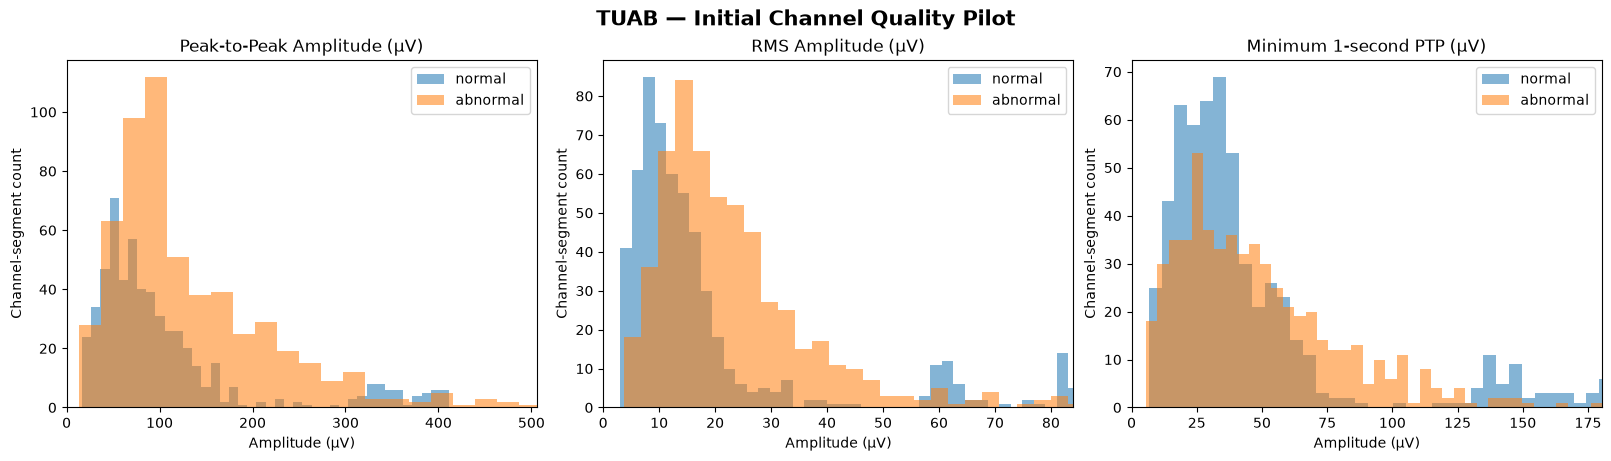

Saved: /home/snow/Documents/Researches/Normal vs Abnormal EEG records using ML/tuab_preprocessing/figures/tuab_initial_channel_qc.png


In [10]:
# Cell C — Visualize initial signal quality

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5),
    constrained_layout=True
)

metrics = [
    ("ptp_uv", "Peak-to-Peak Amplitude (µV)"),
    ("rms_uv", "RMS Amplitude (µV)"),
    ("min_1s_ptp_uv", "Minimum 1-second PTP (µV)")
]

for ax, (metric, title) in zip(axes, metrics):
    for label in ["normal", "abnormal"]:
        values = pilot_qc.loc[
            pilot_qc["label"] == label,
            metric
        ]

        ax.hist(
            values,
            bins=40,
            alpha=0.55,
            label=label
        )

    ax.set_title(title)
    ax.set_xlabel("Amplitude (µV)")
    ax.set_ylabel("Channel-segment count")
    ax.legend()

    # Display zoom only; do not remove observations.
    upper = pilot_qc[metric].quantile(0.99)
    if upper > 0:
        ax.set_xlim(0, upper)

fig.suptitle(
    "TUAB — Initial Channel Quality Pilot",
    fontsize=15,
    fontweight="bold"
)

save_path = (
    FIGURES_DIR / "tuab_initial_channel_qc.png"
)

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", save_path)

# Original reference vs. CAR

In [11]:

STANDARD_CHANNELS = CONFIG["channels"]

def load_car_pilot(label, duration=30):
    path = df.loc[
        (df["split"] == "train") &
        (df["label"] == label),
        "filepath"
    ].iloc[0]

    raw = read_raw_edf_from_archive(
        path,
        preload=False,
        verbose="ERROR"
    )

    try:
        mapping = {}
        for original in raw.ch_names:
            standardized = normalize_channel_name(original)
            if standardized is not None:
                mapping.setdefault(standardized, []).append(original)

        selected = []
        for ch in STANDARD_CHANNELS:
            matches = mapping.get(ch, [])
            if len(matches) != 1:
                raise ValueError(f"Missing/ambiguous channel: {ch}")
            selected.append(matches[0])

        sfreq = raw.info["sfreq"]
        n_samples = int(duration * sfreq)

        start = (raw.n_times - n_samples) // 2
        stop = start + n_samples

        original = raw.get_data(
            picks=selected,
            start=start,
            stop=stop
        ) * 1e6  # microvolts

        # Common Average Reference
        car = original - original.mean(
            axis=0,
            keepdims=True
        )

        return {
            "label": label,
            "filepath": path,
            "sfreq": sfreq,
            "original": original,
            "car": car,
            "times": np.arange(original.shape[1]) / sfreq
        }

    finally:
        raw.close()


normal_pilot = load_car_pilot("normal")
abnormal_pilot = load_car_pilot("abnormal")

print("Normal recording:", normal_pilot["filepath"])
print("Abnormal recording:", abnormal_pilot["filepath"])
print("Signal shape:", normal_pilot["original"].shape)

Normal recording: TUAB/edf/train/normal/01_tcp_ar/aaaaaaav_s004_t000.edf
Abnormal recording: TUAB/edf/train/abnormal/01_tcp_ar/aaaaaaaq_s004_t000.edf
Signal shape: (19, 7500)


# Visualize original EEG vs CAR

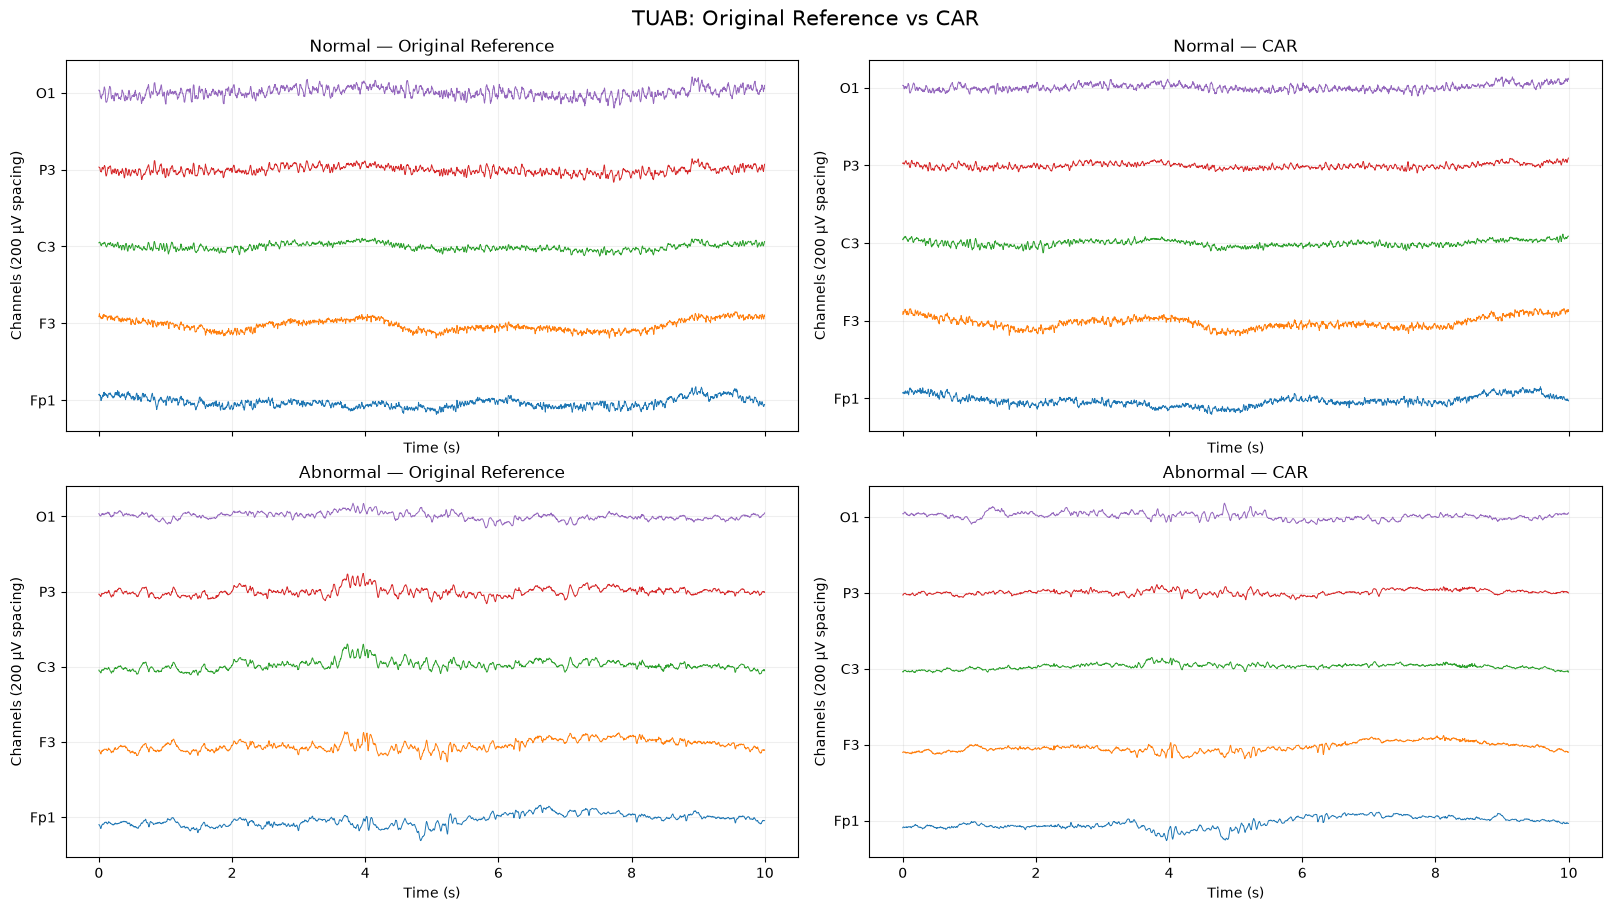

In [12]:
channels_to_plot = ["Fp1", "F3", "C3", "P3", "O1"]
channel_indices = [
    CONFIG["channels"].index(ch)
    for ch in channels_to_plot
]

fig, axes = plt.subplots(
    2, 2, figsize=(16, 9),
    sharex=True, constrained_layout=True
)

for row, pilot in enumerate([normal_pilot, abnormal_pilot]):
    for col, key in enumerate(["original", "car"]):
        ax = axes[row, col]

        # Display the first 10 seconds for readability.
        n = int(10 * pilot["sfreq"])
        signals = pilot[key][channel_indices, :n]

        offsets = np.arange(len(channels_to_plot)) * 200

        for i, ch in enumerate(channels_to_plot):
            ax.plot(
                pilot["times"][:n],
                signals[i] + offsets[i],
                linewidth=0.7
            )

        ax.set_yticks(offsets)
        ax.set_yticklabels(channels_to_plot)
        ax.set_title(
            f"{pilot['label'].capitalize()} — "
            f"{'Original Reference' if key == 'original' else 'CAR'}"
        )
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Channels (200 µV spacing)")
        ax.grid(alpha=0.2)

fig.suptitle(
    "TUAB: Original Reference vs CAR",
    fontsize=15
)

fig.savefig(
    FIGURES_DIR / "tuab_car_waveform_comparison.png",
    dpi=300, bbox_inches="tight"
)

plt.show()
plt.close(fig)

# PSD comparison

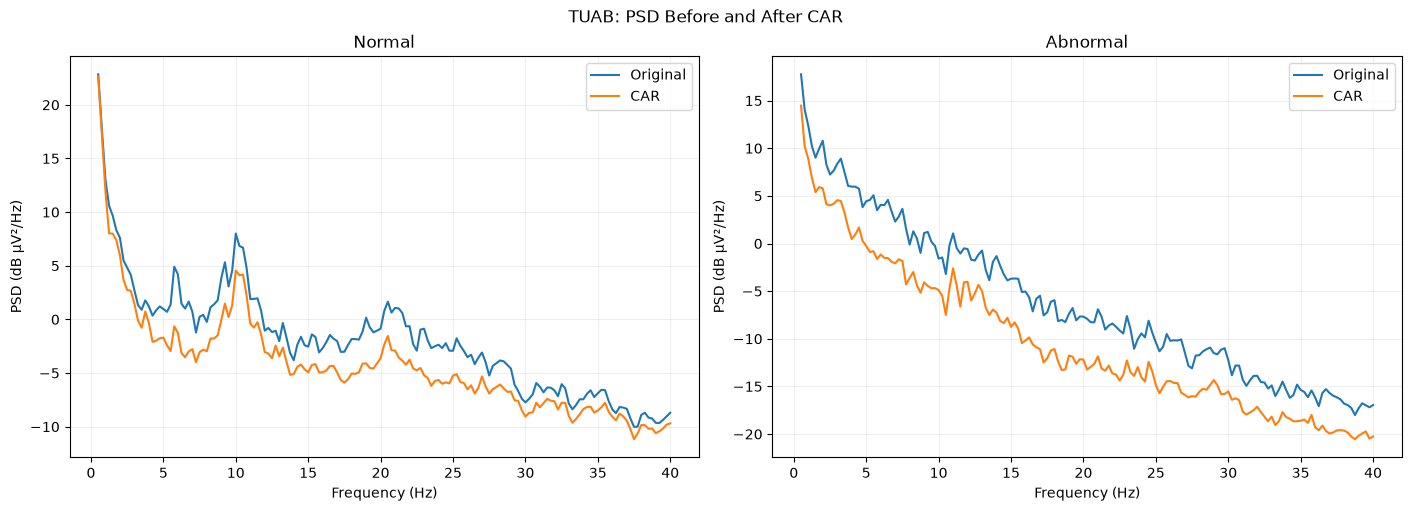

In [13]:

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5),
    constrained_layout=True
)

for ax, pilot in zip(
    axes, [normal_pilot, abnormal_pilot]
):
    for key, name in [
        ("original", "Original"),
        ("car", "CAR")
    ]:
        freqs, psd = welch(
            pilot[key],
            fs=pilot["sfreq"],
            nperseg=int(4 * pilot["sfreq"]),
            axis=-1
        )

        mean_psd = psd.mean(axis=0)
        mask = (freqs >= 0.5) & (freqs <= 40)

        ax.plot(
            freqs[mask],
            10 * np.log10(mean_psd[mask] + 1e-20),
            label=name
        )# PSD comparison

    ax.set_title(pilot["label"].capitalize())
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (dB µV²/Hz)")
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle("TUAB: PSD Before and After CAR")

fig.savefig(
    FIGURES_DIR / "tuab_car_psd_comparison.png",
    dpi=300, bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Quantitative validation

In [14]:
results = []

for pilot in [normal_pilot, abnormal_pilot]:
    for i, channel in enumerate(CONFIG["channels"]):
        original = pilot["original"][i]
        car = pilot["car"][i]

        results.append({
            "label": pilot["label"],
            "channel": channel,
            "original_rms_uv": np.sqrt(np.mean(original**2)),
            "car_rms_uv": np.sqrt(np.mean(car**2)),
            "original_ptp_uv": np.ptp(original),
            "car_ptp_uv": np.ptp(car)
        })

car_metrics = pd.DataFrame(results)

display(
    car_metrics.groupby("label")[
        [
            "original_rms_uv",
            "car_rms_uv",
            "original_ptp_uv",
            "car_ptp_uv"
        ]
    ].median().round(2)
)

car_metrics.to_csv(
    METADATA_DIR / "tuab_car_pilot_metrics.csv",
    index=False
)

,original_rms_uv,car_rms_uv,original_ptp_uv,car_ptp_uv
label,,,,
abnormal,12.71,9.25,122.99,60.06
normal,12.11,8.02,101.62,66.27


# Verify CAR mathematically

In [15]:
for pilot in [normal_pilot, abnormal_pilot]:
    car_mean = pilot["car"].mean(axis=0)

    max_error = np.max(np.abs(car_mean))

    print(
        f"{pilot['label']}: "
        f"maximum CAR mean error = {max_error:.3e} µV"
    )

    assert np.allclose(
        car_mean, 0.0, atol=1e-10
    )

print("CAR mathematical validation: PASSED")

normal: maximum CAR mean error = 9.349e-15 µV
abnormal: maximum CAR mean error = 1.365e-14 µV
CAR mathematical validation: PASSED


# Bandpass filtering and resampling

In [16]:
def filter_and_resample(pilot):
    sfreq = pilot["sfreq"]

    # Convert µV back to volts for MNE
    data_volts = pilot["original"] * 1e-6

    info = mne.create_info(
        ch_names=CONFIG["channels"],
        sfreq=sfreq,
        ch_types="eeg"
    )

    raw = mne.io.RawArray(
        data_volts,
        info,
        verbose="ERROR"
    )

    # Bandpass filtering
    raw.filter(
        l_freq=0.5,
        h_freq=40.0,
        method="fir",
        phase="zero",
        fir_design="firwin",
        verbose="ERROR"
    )

    filtered = raw.get_data() * 1e6

    # Resampling with anti-alias filtering
    raw.resample(
        sfreq=200,
        method="fft",
        verbose="ERROR"
    )

    resampled = raw.get_data() * 1e6

    return {
        "label": pilot["label"],
        "original": pilot["original"],
        "filtered": filtered,
        "resampled": resampled,
        "original_sfreq": sfreq,
        "target_sfreq": raw.info["sfreq"]
    }


normal_processed = filter_and_resample(normal_pilot)
abnormal_processed = filter_and_resample(abnormal_pilot)

for p in [normal_processed, abnormal_processed]:
    print(f"\n{p['label'].capitalize()}")
    print("Original:", p["original"].shape)
    print("Filtered:", p["filtered"].shape)
    print("Resampled:", p["resampled"].shape)
    print("Final frequency:", p["target_sfreq"])


Normal
Original: (19, 7500)
Filtered: (19, 7500)
Resampled: (19, 6000)
Final frequency: 200.0

Abnormal
Original: (19, 7500)
Filtered: (19, 7500)
Resampled: (19, 6000)
Final frequency: 200.0


# PSD before and after filtering

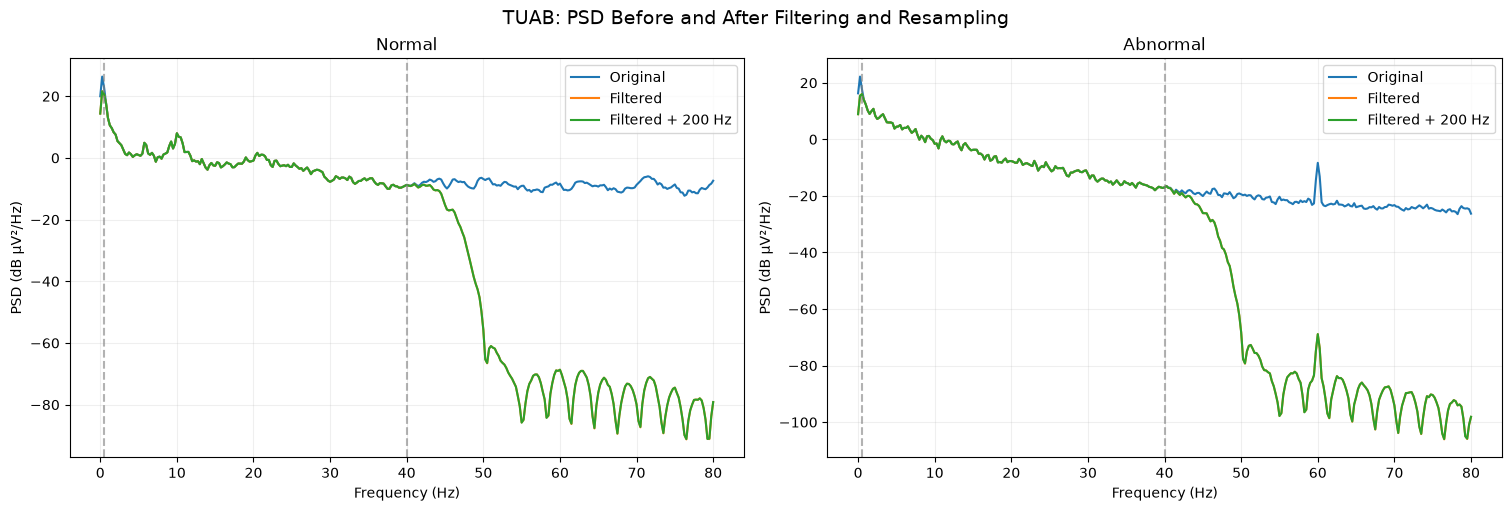

In [17]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    constrained_layout=True
)

for ax, p in zip(
    axes,
    [normal_processed, abnormal_processed]
):
    for key, sfreq, label in [
        ("original", p["original_sfreq"], "Original"),
        ("filtered", p["original_sfreq"], "Filtered"),
        ("resampled", p["target_sfreq"], "Filtered + 200 Hz")
    ]:
        freqs, psd = welch(
            p[key],
            fs=sfreq,
            nperseg=int(4 * sfreq),
            axis=-1
        )

        mean_psd = psd.mean(axis=0)

        mask = (freqs >= 0) & (freqs <= 80)

        ax.plot(
            freqs[mask],
            10 * np.log10(mean_psd[mask] + 1e-20),
            label=label
        )

    ax.axvline(0.5, color="gray", linestyle="--", alpha=0.6)
    ax.axvline(40, color="gray", linestyle="--", alpha=0.6)

    ax.set_title(p["label"].capitalize())
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (dB µV²/Hz)")
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle(
    "TUAB: PSD Before and After Filtering and Resampling",
    fontsize=14
)

fig.savefig(
    FIGURES_DIR / "tuab_filter_resample_psd.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

In [18]:
# Validate the output
for p in [normal_processed, abnormal_processed]:

    assert p["resampled"].shape[0] == 19

    expected_samples = int(
        p["original"].shape[1]
        / p["original_sfreq"]
        * 200
    )

    assert p["resampled"].shape[1] == expected_samples

    assert p["target_sfreq"] == 200

    assert np.isfinite(p["resampled"]).all()

    print(
        f"{p['label']}: PASSED — "
        f"{p['resampled'].shape}, "
        f"{p['target_sfreq']} Hz"
    )

print("validation: PASSED")

normal: PASSED — (19, 6000), 200.0 Hz
abnormal: PASSED — (19, 6000), 200.0 Hz
validation: PASSED


# Apply CAR at 200 Hz

In [19]:
def apply_car(processed):
    # Input: filtered and resampled EEG in µV
    eeg = processed["resampled"]

    assert eeg.shape[0] == 19
    assert processed["target_sfreq"] == 200

    # Common Average Reference across channels
    common_average = eeg.mean(axis=0, keepdims=True)
    eeg_car = eeg - common_average

    return {
        **processed,
        "car_200hz": eeg_car,
        "common_average": common_average
    }


normal_processed = apply_car(normal_processed)
abnormal_processed = apply_car(abnormal_processed)

for p in [normal_processed, abnormal_processed]:
    print(f"\n{p['label'].capitalize()}")
    print("Before CAR:", p["resampled"].shape)
    print("After CAR: ", p["car_200hz"].shape)


Normal
Before CAR: (19, 6000)
After CAR:  (19, 6000)

Abnormal
Before CAR: (19, 6000)
After CAR:  (19, 6000)


# Mathematical validation

In [20]:
for p in [normal_processed, abnormal_processed]:
    eeg_car = p["car_200hz"]

    # Average across channels at every time point
    channel_mean = eeg_car.mean(axis=0)

    max_error = np.max(np.abs(channel_mean))

    assert np.allclose(
        channel_mean,
        0.0,
        atol=1e-10
    )

    assert np.isfinite(eeg_car).all()

    print(
        f"{p['label']}: "
        f"max CAR mean error = {max_error:.3e} µV"
    )

print("\nCell 6 CAR validation: PASSED")

normal: max CAR mean error = 5.142e-15 µV
abnormal: max CAR mean error = 8.040e-15 µV

Cell 6 CAR validation: PASSED


# Compare amplitudes before and after CAR

In [21]:
results = []

for p in [normal_processed, abnormal_processed]:
    before = p["resampled"]
    after = p["car_200hz"]

    for i, channel in enumerate(CONFIG["channels"]):
        results.append({
            "label": p["label"],
            "channel": channel,
            "rms_before_uv": np.sqrt(np.mean(before[i] ** 2)),
            "rms_after_uv": np.sqrt(np.mean(after[i] ** 2)),
            "ptp_before_uv": np.ptp(before[i]),
            "ptp_after_uv": np.ptp(after[i])
        })

car_200hz_metrics = pd.DataFrame(results)

display(
    car_200hz_metrics.groupby("label")[
        [
            "rms_before_uv",
            "rms_after_uv",
            "ptp_before_uv",
            "ptp_after_uv"
        ]
    ].median().round(2)
)

car_200hz_metrics.to_csv(
    METADATA_DIR / "tuab_car_200hz_metrics.csv",
    index=False
)

,rms_before_uv,rms_after_uv,ptp_before_uv,ptp_after_uv
label,,,,
abnormal,8.62,4.78,83.27,47.71
normal,9.23,6.21,69.67,47.03


# 8-second EEG epochs

In [22]:
def create_epochs(processed, epoch_seconds=8):
    eeg = processed["car_200hz"]
    sfreq = processed["target_sfreq"]

    samples_per_epoch = int(epoch_seconds * sfreq)
    n_epochs = eeg.shape[1] // samples_per_epoch

    # Remove incomplete final window
    eeg = eeg[:, :n_epochs * samples_per_epoch]

    # (epochs, channels, samples)
    epochs = eeg.reshape(
        eeg.shape[0],
        n_epochs,
        samples_per_epoch
    ).transpose(1, 0, 2)

    return epochs


normal_epochs = create_epochs(normal_processed)
abnormal_epochs = create_epochs(abnormal_processed)

print("Normal epochs:", normal_epochs.shape)
print("Abnormal epochs:", abnormal_epochs.shape)

assert normal_epochs.shape == (3, 19, 1600)
assert abnormal_epochs.shape == (3, 19, 1600)

print("epoching validation: PASSED")

Normal epochs: (3, 19, 1600)
Abnormal epochs: (3, 19, 1600)
epoching validation: PASSED


# Calculate epoch quality metrics
* Peak-to-peak amplitude (PTP) ==> (Detect unusually large voltage excursions)
* RMS Amplitude                ==> (Measure overall signal amplitude)
* Minimum 1-second PTP         ==> (Screen for potentially flat channels)
* Maximum absolute amplitude   ==> (Flag extreme excursions)

In [23]:
SFREQ = 200
CHANNELS = CONFIG["channels"]

def calculate_epoch_qc(epochs, label):
    records = []

    for epoch_idx, epoch in enumerate(epochs):
        for channel_idx, channel in enumerate(CHANNELS):
            signal = epoch[channel_idx]

            ptp = np.ptp(signal)
            rms = np.sqrt(np.mean(signal ** 2))
            max_abs = np.max(np.abs(signal))

            # 8 non-overlapping 1-second subwindows
            one_second = signal.reshape(8, SFREQ)
            min_1s_ptp = np.ptp(one_second, axis=1).min()

            records.append({
                "label": label,
                "epoch": epoch_idx,
                "channel": channel,
                "ptp_uv": ptp,
                "rms_uv": rms,
                "max_abs_uv": max_abs,
                "min_1s_ptp_uv": min_1s_ptp
            })

    return pd.DataFrame(records)


normal_qc = calculate_epoch_qc(normal_epochs, "normal")
abnormal_qc = calculate_epoch_qc(abnormal_epochs, "abnormal")

epoch_qc = pd.concat(
    [normal_qc, abnormal_qc],
    ignore_index=True
)

display(
    epoch_qc.groupby("label")[
        ["ptp_uv", "rms_uv", "max_abs_uv", "min_1s_ptp_uv"]
    ].describe().round(2)
)

epoch_qc.to_csv(
    METADATA_DIR / "tuab_epoch_qc_pilot.csv",
    index=False
)

ptp_uv                                                   rms_uv  \
          count   mean    std    min    25%    50%    75%     max  count   
label                                                                      
abnormal   57.0  32.98  12.57  17.96  22.27  29.41  39.85   68.02   57.0   
normal     57.0  47.20  31.07  21.67  31.47  36.32  48.05  156.66   57.0   

                ... max_abs_uv        min_1s_ptp_uv                      \
          mean  ...        75%    max         count   mean   std    min   
label           ...                                                       
abnormal  4.84  ...      20.93  42.04          57.0  12.52  2.49   7.25   
normal    8.10  ...      25.42  95.84          57.0  19.31  5.72  10.17   

                                      
            25%    50%    75%    max  
label                                 
abnormal  10.93  12.35  13.49  18.88  
normal    15.60  17.70  22.79  39.40  

[2 rows x 32 columns]

# Generate QC flags

In [24]:
epoch_qc["high_amplitude_flag"] = (
    epoch_qc["ptp_uv"] > 500
)

epoch_qc["possible_flatline_flag"] = (
    epoch_qc["min_1s_ptp_uv"] < 1
)

epoch_qc["suspect_flag"] = (
    epoch_qc["high_amplitude_flag"] |
    epoch_qc["possible_flatline_flag"]
)

print("Total channel-epoch observations:", len(epoch_qc))
print("High-amplitude flags:", epoch_qc["high_amplitude_flag"].sum())
print("Possible flatline flags:", epoch_qc["possible_flatline_flag"].sum())

display(
    epoch_qc.groupby("label")[
        [
            "high_amplitude_flag",
            "possible_flatline_flag",
            "suspect_flag"
        ]
    ].sum()
)

Total channel-epoch observations: 114
High-amplitude flags: 0
Possible flatline flags: 0


,high_amplitude_flag,possible_flatline_flag,suspect_flag
label,,,
abnormal,0,0,0
normal,0,0,0


# Aggregate QC at epoch level

In [25]:
epoch_summary = (
    epoch_qc
    .groupby(["label", "epoch"], as_index=False)
    .agg(
        suspect_channels=("suspect_flag", "sum"),
        high_amplitude_channels=("high_amplitude_flag", "sum"),
        possible_flatline_channels=("possible_flatline_flag", "sum"),
        max_ptp_uv=("ptp_uv", "max"),
        max_abs_uv=("max_abs_uv", "max")
    )
)

epoch_summary["qc_status"] = np.where(
    epoch_summary["suspect_channels"] > 0,
    "SUSPECT",
    "NO_SCREENING_FLAGS"
)

display(epoch_summary)

epoch_summary.to_csv(
    METADATA_DIR / "tuab_epoch_qc_summary_pilot.csv",
    index=False
)

,label,epoch,suspect_channels,high_amplitude_channels,possible_flatline_channels,max_ptp_uv,max_abs_uv,qc_status
0,abnormal,0,0,0,0,68.018106,42.039785,NO_SCREENING_FLAGS
1,abnormal,1,0,0,0,31.589625,17.880373,NO_SCREENING_FLAGS
2,abnormal,2,0,0,0,38.740470,21.173228,NO_SCREENING_FLAGS
3,normal,0,0,0,0,110.396904,60.308646,NO_SCREENING_FLAGS
4,normal,1,0,0,0,156.655211,95.838080,NO_SCREENING_FLAGS
5,normal,2,0,0,0,75.613959,40.589961,NO_SCREENING_FLAGS


# Verify epoch preservation

In [26]:
total_epochs = len(normal_epochs) + len(abnormal_epochs)

assert len(epoch_summary) == total_epochs
assert len(epoch_qc) == total_epochs * 19

assert np.isfinite(normal_epochs).all()
assert np.isfinite(abnormal_epochs).all()

print("Total epochs:", total_epochs)
print("Epochs rejected:", 0)
print("Epochs preserved:", total_epochs)

print("\nCell 8 QC pilot: PASSED")

Total epochs: 6
Epochs rejected: 0
Epochs preserved: 6

Cell 8 QC pilot: PASSED


# Process 12 recordings

In [27]:

pilot_candidates = df[df["split"] == "train"].merge(
    channel_audit[["filepath", "sfreq"]],
    on="filepath",
    how="left",
    validate="one_to_one"
)

assert pilot_candidates["sfreq"].notna().all()

selected_parts = []

for sfreq in sorted(pilot_candidates["sfreq"].unique()):
    for label in ["normal", "abnormal"]:
        subset = pilot_candidates[
            (pilot_candidates["sfreq"] == sfreq) &
            (pilot_candidates["label"] == label)
        ]

        if len(subset):
            selected_parts.append(
                subset.sample(
                    n=min(2, len(subset)),
                    random_state=42
                )
            )

pilot_df = pd.concat(
    selected_parts,
    ignore_index=True
).drop_duplicates("filepath")

display(
    pilot_df[
        ["filename", "label", "sfreq"]
    ]
)

print("Selected recordings:", len(pilot_df))

,filename,label,sfreq
0,aaaaalgg_s001_t000.edf,normal,250.0
1,aaaaapoe_s001_t000.edf,normal,250.0
2,aaaaanws_s003_t000.edf,abnormal,250.0
3,aaaaadji_s006_t000.edf,abnormal,250.0
4,aaaaapms_s001_t001.edf,normal,256.0
5,aaaaaptb_s001_t001.edf,normal,256.0
6,aaaaaool_s005_t003.edf,abnormal,256.0
7,aaaaamuy_s006_t010.edf,abnormal,256.0
8,aaaaaocl_s006_t000.edf,normal,512.0
9,aaaaaenq_s006_t002.edf,normal,512.0


Selected recordings: 12


In [28]:
CHANNELS = CONFIG["channels"]
TARGET_SFREQ = 200
EPOCH_SECONDS = 8

def process_full_recording(filepath):
    start_time = time.perf_counter()

    raw = read_raw_edf_from_archive(
        filepath,
        preload=True,
        verbose="ERROR"
    )

    try:
        mapping = {}
        for original in raw.ch_names:
            standardized = normalize_channel_name(original)
            if standardized in CHANNELS:
                mapping.setdefault(
                    standardized, []
                ).append(original)

        selected = []

        for channel in CHANNELS:
            matches = mapping.get(channel, [])
            if len(matches) != 1:
                raise ValueError(
                    f"Missing or duplicate channel: {channel}"
                )
            selected.append(matches[0])

        raw.pick(selected)
        raw.rename_channels({
            original: standard
            for original, standard in zip(
                selected, CHANNELS
            )
        })
        raw.reorder_channels(CHANNELS)

        original_sfreq = raw.info["sfreq"]
        original_samples = raw.n_times

        # Raw technical QC, before filtering/CAR
        raw_data = raw.get_data()

        nonfinite_count = int(
            (~np.isfinite(raw_data)).sum()
        )

        # Exploratory flatline screening
        samples_1s = int(original_sfreq)
        complete_seconds = (
            raw_data.shape[1] // samples_1s
        )

        one_second = raw_data[
            :, :complete_seconds * samples_1s
        ].reshape(
            len(CHANNELS),
            complete_seconds,
            samples_1s
        )

        ptp_1s_uv = np.ptp(
            one_second, axis=2
        ) * 1e6

        possible_flatline_channels = int(
            (ptp_1s_uv < 1.0).any(axis=1).sum()
        )

        del raw_data, one_second, ptp_1s_uv

        # Bandpass: 0.5–40 Hz
        raw.filter(
            l_freq=0.5,
            h_freq=40.0,
            method="fir",
            phase="zero",
            fir_design="firwin",
            verbose="ERROR"
        )

        # Harmonize sampling frequency
        if raw.info["sfreq"] != TARGET_SFREQ:
            raw.resample(
                TARGET_SFREQ,
                method="fft",
                verbose="ERROR"
            )

        # Save the pre-CAR signal for reference experiments
        eeg_pre_car = raw.get_data() * 1e6

        # CAR across 19 channels
        eeg_car = eeg_pre_car - eeg_pre_car.mean(
            axis=0,
            keepdims=True
        )

        car_error = float(
            np.abs(eeg_car.mean(axis=0)).max()
        )

        # Non-overlapping 8-second epochs
        samples_per_epoch = (
            TARGET_SFREQ * EPOCH_SECONDS
        )

        n_epochs = (
            eeg_car.shape[1] // samples_per_epoch
        )

        epochs = eeg_car[
            :, :n_epochs * samples_per_epoch
        ].reshape(
            len(CHANNELS),
            n_epochs,
            samples_per_epoch
        ).transpose(1, 0, 2)

        assert epochs.shape[1:] == (19, 1600)
        assert np.isfinite(epochs).all()
        assert car_error < 1e-10

        result = {
            "filepath": str(filepath),
            "original_sfreq": original_sfreq,
            "original_samples": original_samples,
            "processed_samples": eeg_car.shape[1],
            "n_epochs": n_epochs,
            "possible_flatline_channels": (
                possible_flatline_channels
            ),
            "nonfinite_samples": nonfinite_count,
            "car_max_error_uv": car_error,
            "runtime_seconds": (
                time.perf_counter() - start_time
            )
        }

        return result

    finally:
        raw.close()
        gc.collect()

In [29]:

pilot_results = []
pilot_errors = []

for row in tqdm(
    pilot_df.itertuples(index=False),
    total=len(pilot_df),
    desc="Full-recording pilot"
):
    try:
        result = process_full_recording(
            row.filepath
        )

        result["label"] = row.label
        result["split"] = row.split

        pilot_results.append(result)

    except Exception as error:
        pilot_errors.append({
            "filepath": row.filepath,
            "error": str(error)
        })

pilot_results_df = pd.DataFrame(pilot_results)
pilot_errors_df = pd.DataFrame(pilot_errors)

pilot_results_df.to_csv(
    METADATA_DIR / "tuab_full_recording_pilot.csv",
    index=False
)

pilot_errors_df.to_csv(
    METADATA_DIR / "tuab_full_recording_errors.csv",
    index=False
)

print("Successful recordings:", len(pilot_results_df))
print("Errors:", len(pilot_errors_df))

if len(pilot_results_df):
    display(
        pilot_results_df[
            [
                "original_sfreq",
                "n_epochs",
                "possible_flatline_channels",
                "car_max_error_uv",
                "runtime_seconds"
            ]
        ]
    )

if len(pilot_errors_df):
    display(pilot_errors_df)

Full-recording pilot:   0%|          | 0/12 [00:00<?, ?it/s]

Successful recordings: 12
Errors: 0


,original_sfreq,n_epochs,possible_flatline_channels,car_max_error_uv,runtime_seconds
0,250.0,165,0,2.243819e-14,0.943129
1,250.0,153,0,6.701540e-13,0.750205
2,250.0,158,0,2.916965e-14,0.708404
3,250.0,169,0,2.019437e-14,0.793164
4,256.0,158,0,4.786814e-14,0.627352
5,256.0,166,0,1.017198e-13,0.678624
6,256.0,158,0,1.364990e-14,0.628617
7,256.0,244,0,7.180221e-14,0.873044
8,512.0,337,0,9.050071e-14,3.212579
9,512.0,213,19,1.271498e-13,1.574477


In [30]:
assert len(pilot_errors_df) == 0
assert len(pilot_results_df) == len(pilot_df)

print("Total epochs:", pilot_results_df["n_epochs"].sum())

print(
    "Total processing time (seconds):",
    round(
        pilot_results_df["runtime_seconds"].sum(),
        2
    )
)

print(
    "Recordings with possible flatlines:",
    int(
        (
            pilot_results_df[
                "possible_flatline_channels"
            ] > 0
        ).sum()
    )
)

print(
    "Maximum CAR error (µV):",
    pilot_results_df["car_max_error_uv"].max()
)

print("\nCell 9 full-recording pilot: PASSED")

Total epochs: 2230
Total processing time (seconds): 13.31
Recordings with possible flatlines: 2
Maximum CAR error (µV): 6.701539907800523e-13

Cell 9 full-recording pilot: PASSED


# Investigate the flatline warnings

In [31]:
flagged_files = pilot_results_df.loc[
    pilot_results_df["possible_flatline_channels"] > 0,
    "filepath"
]

flatline_events = []

for filepath in flagged_files:
    raw = read_raw_edf_from_archive(
        filepath, preload=False, verbose="ERROR"
    )

    try:
        mapping = {}
        for name in raw.ch_names:
            standard = normalize_channel_name(name)
            if standard in CONFIG["channels"]:
                mapping[standard] = name

        selected = [
            mapping[ch] for ch in CONFIG["channels"]
        ]

        sfreq = raw.info["sfreq"]
        samples_per_second = int(sfreq)

        data = raw.get_data(picks=selected) * 1e6

        n_seconds = data.shape[1] // samples_per_second

        windows = data[
            :, :n_seconds * samples_per_second
        ].reshape(19, n_seconds, samples_per_second)

        ptp = np.ptp(windows, axis=2)
        flat = ptp < 1.0

        simultaneous_counts = flat.sum(axis=0)

        for second in np.where(simultaneous_counts > 0)[0]:
            flatline_events.append({
                "filename": Path(filepath).name,
                "second": int(second),
                "flat_channels": int(
                    simultaneous_counts[second]
                ),
                "all_19_flat": bool(
                    simultaneous_counts[second] == 19
                )
            })

    finally:
        raw.close()

flatline_events_df = pd.DataFrame(flatline_events)

if len(flatline_events_df):
    display(
        flatline_events_df.groupby("filename").agg(
            flagged_seconds=("second", "count"),
            first_flagged_second=("second", "min"),
            last_flagged_second=("second", "max"),
            seconds_all_19_flat=("all_19_flat", "sum"),
            max_simultaneous_channels=("flat_channels", "max")
        )
    )

    flatline_events_df.to_csv(
        METADATA_DIR / "tuab_flatline_events_pilot.csv",
        index=False
    )

,flagged_seconds,first_flagged_second,last_flagged_second,seconds_all_19_flat,max_simultaneous_channels
filename,,,,,
aaaaacrz_s003_t004.edf,2,1350,1351,2,19
aaaaaenq_s006_t002.edf,1,1708,1708,1,19


# Visual inspection of flagged intervals

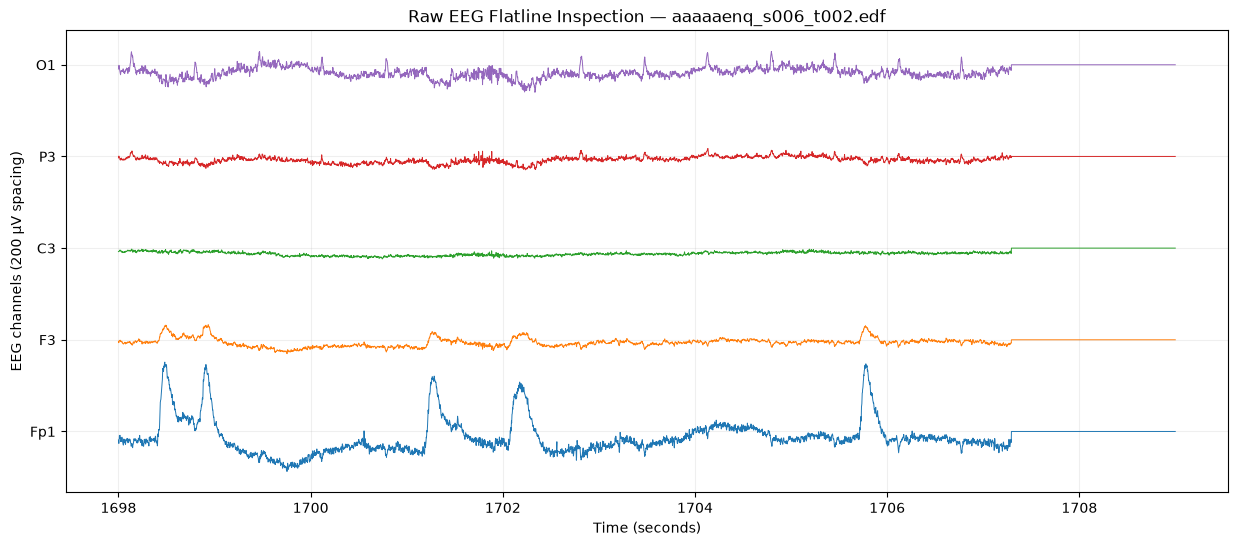

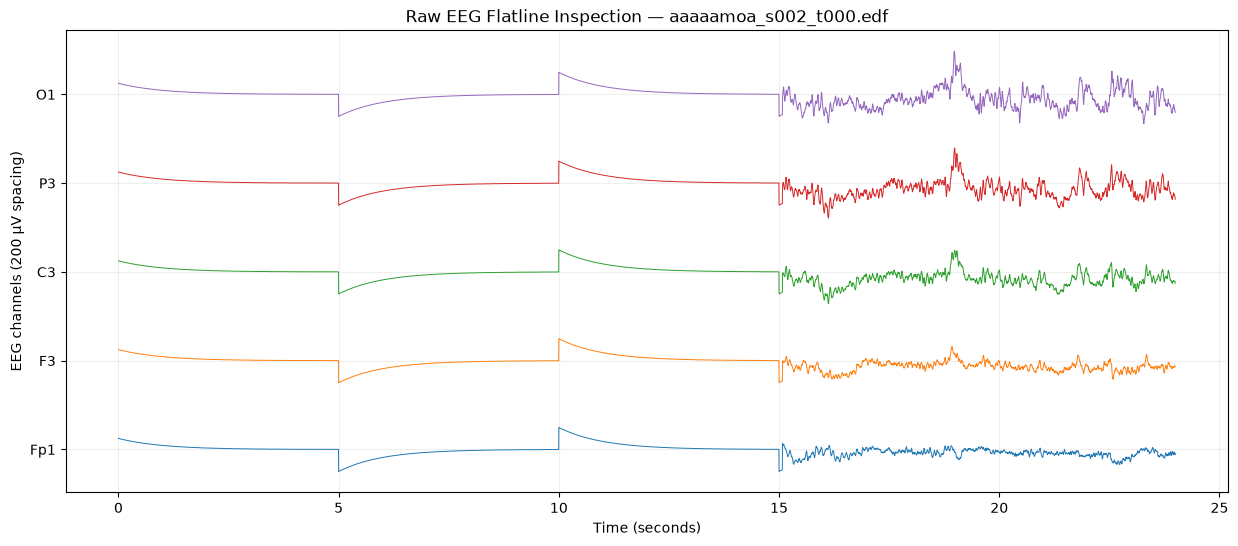

In [33]:
flagged_intervals = {
    "aaaaaenq_s006_t002.edf": (1698, 1718),
    "aaaaamoa_s002_t000.edf": (0, 24),
}

channels_to_plot = ["Fp1", "F3", "C3", "P3", "O1"]

for filename, (start_sec, end_sec) in flagged_intervals.items():

    matches = df.loc[
        df["filename"] == filename,
        "filepath",
    ]

    if matches.empty:
        print(f"Recording not found in TUAB.zip: {filename}")
        continue

    filepath = matches.iloc[0]

    raw = read_raw_edf_from_archive(
        filepath,
        preload=False,
        verbose="ERROR",
    )

    try:
        mapping = {
            normalize_channel_name(channel): channel
            for channel in raw.ch_names
        }

        missing_channels = [
            channel
            for channel in channels_to_plot
            if channel not in mapping
        ]

        if missing_channels:
            raise ValueError(
                f"{filename} is missing channels: {missing_channels}"
            )

        selected = [
            mapping[channel]
            for channel in channels_to_plot
        ]

        sfreq = raw.info["sfreq"]

        data = raw.get_data(
            picks=selected,
            start=int(start_sec * sfreq),
            stop=int(end_sec * sfreq),
        ) * 1e6

        times = start_sec + np.arange(data.shape[1]) / sfreq

        fig, ax = plt.subplots(figsize=(15, 6))
        offsets = np.arange(len(channels_to_plot)) * 200

        for i, channel in enumerate(channels_to_plot):
            ax.plot(
                times,
                data[i] + offsets[i],
                linewidth=0.7,
            )

        ax.set_yticks(offsets)
        ax.set_yticklabels(channels_to_plot)
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("EEG channels (200 µV spacing)")
        ax.set_title(f"Raw EEG Flatline Inspection — {filename}")
        ax.grid(alpha=0.2)

        save_path = (
            FIGURES_DIR
            / f"flatline_inspection_{Path(filename).stem}.png"
        )

        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()
        plt.close(fig)

    finally:
        raw.close()

In [35]:
# Verify the exact affected intervals.
# Technical artifacts could otherwise influence both abnormality
# classification and spatial explanations.

for filename in [
    "aaaaaenq_s006_t002.edf",
    "aaaaamoa_s002_t000.edf",
]:
    matches = df.loc[
        df["filename"] == filename,
        "filepath",
    ]

    if matches.empty:
        print(f"Recording not found in TUAB.zip: {filename}")
        continue

    filepath = matches.iloc[0]

    raw = read_raw_edf_from_archive(
        filepath,
        preload=False,
        verbose="ERROR",
    )

    try:
        events = flatline_events_df.loc[
            flatline_events_df["filename"] == filename
        ].sort_values("second")

        if events.empty:
            print(
                f"\n{filename}: no events are available in "
                "flatline_events_df because this recording was not "
                "included in the current pilot sample."
            )
            continue

        all_flat = events.loc[
            events["all_19_flat"],
            "second",
        ].tolist()

        print(f"\n{filename}")
        print(
            f"Duration: "
            f"{raw.n_times / raw.info['sfreq']:.2f} s"
        )
        print(f"All-19-channel flat seconds: {all_flat}")
        print(
            "Last flat second:",
            max(all_flat) if all_flat else None,
        )

    finally:
        raw.close()


aaaaaenq_s006_t002.edf
Duration: 1709.00 s
All-19-channel flat seconds: [1708]
Last flat second: 1708

aaaaamoa_s002_t000.edf: no events are available in flatline_events_df because this recording was not included in the current pilot sample.


# Create an auditable exclusion table

In [36]:

qc_exclusions = pd.DataFrame([
    {
        "filename": "aaaaamoa_s002_t000.edf",
        "epoch_index": 0,
        "start_sec": 0,
        "end_sec": 8,
        "reason": "Recording-wide technical artifact",
        "status": "PROVISIONAL_EXCLUDE"
    },
    {
        "filename": "aaaaamoa_s002_t000.edf",
        "epoch_index": 1,
        "start_sec": 8,
        "end_sec": 16,
        "reason": "Recording-wide technical artifact",
        "status": "PROVISIONAL_EXCLUDE"
    }
])

qc_exclusions.to_csv(
    METADATA_DIR / "tuab_pilot_epoch_exclusions.csv",
    index=False
)

display(qc_exclusions)

print("Provisional excluded epochs:", len(qc_exclusions))
print("Pilot epochs before QC:", 1947)
print("Pilot epochs after provisional QC:", 1947 - len(qc_exclusions))

,filename,epoch_index,start_sec,end_sec,reason,status
0,aaaaamoa_s002_t000.edf,0,0,8,Recording-wide technical artifact,PROVISIONAL_EXCLUDE
1,aaaaamoa_s002_t000.edf,1,8,16,Recording-wide technical artifact,PROVISIONAL_EXCLUDE


Provisional excluded epochs: 2
Pilot epochs before QC: 1947
Pilot epochs after provisional QC: 1945


# Process 100 recordings

In [37]:
# Configuration and select 100 recordings

BATCH_DIR = OUTPUT_DIR / "batch_100"
EPOCH_DIR = BATCH_DIR / "epochs"
QC_DIR = BATCH_DIR / "qc"

for folder in [BATCH_DIR, EPOCH_DIR, QC_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

CHANNELS = CONFIG["channels"]
TARGET_SFREQ = 200
EPOCH_SECONDS = 8
SAMPLES_PER_EPOCH = 1600

# Balanced selection from the development-training partition
batch_df = (
    df[df["split"] == "train"]
    .groupby("label", group_keys=False)
    .sample(n=50, random_state=42)
    .reset_index(drop=True)
)

assert len(batch_df) == 100
assert batch_df["patient_id"].notna().all()

print(pd.crosstab(batch_df["split"], batch_df["label"]))
print("Selected recordings:", len(batch_df))

label  abnormal  normal
split                  
train        50      50
Selected recordings: 100


In [38]:
# Production preprocessing function
def preprocess_recording(row):
    filepath = Path(row.filepath)
    start_time = time.perf_counter()

    raw = read_raw_edf_from_archive(
        filepath,
        preload=True,
        verbose="ERROR"
    )

    try:
        mapping = {}

        for original in raw.ch_names:
            standard = normalize_channel_name(original)

            if standard in CHANNELS:
                mapping.setdefault(standard, []).append(original)

        selected = []

        for channel in CHANNELS:
            matches = mapping.get(channel, [])

            if len(matches) != 1:
                raise ValueError(
                    f"Missing/duplicate channel: {channel}"
                )

            selected.append(matches[0])

        raw.pick(selected)

        raw.rename_channels({
            original: standard
            for original, standard in zip(selected, CHANNELS)
        })

        raw.reorder_channels(CHANNELS)

        original_sfreq = float(raw.info["sfreq"])

        # -----------------------------------
        # 1. Raw technical QC
        # -----------------------------------
        raw_data_uv = raw.get_data() * 1e6

        if not np.isfinite(raw_data_uv).all():
            raise ValueError("Non-finite raw EEG samples")

        raw_1s_samples = int(round(original_sfreq))
        n_raw_seconds = raw_data_uv.shape[1] // raw_1s_samples

        raw_windows = raw_data_uv[
            :, :n_raw_seconds * raw_1s_samples
        ].reshape(
            19, n_raw_seconds, raw_1s_samples
        )

        raw_1s_ptp = np.ptp(raw_windows, axis=2)
        raw_flat_seconds = (
            raw_1s_ptp < 1.0
        ).any(axis=0)

        # -----------------------------------
        # 2. Filter and resample
        # -----------------------------------
        del raw_data_uv, raw_windows, raw_1s_ptp

        raw.filter(
            l_freq=0.5,
            h_freq=40.0,
            method="fir",
            phase="zero",
            fir_design="firwin",
            verbose="ERROR"
        )

        if raw.info["sfreq"] != TARGET_SFREQ:
            raw.resample(
                TARGET_SFREQ,
                method="fft",
                verbose="ERROR"
            )

        # -----------------------------------
        # 3. CAR
        # -----------------------------------
        eeg_uv = raw.get_data() * 1e6

        eeg_car = eeg_uv - eeg_uv.mean(
            axis=0,
            keepdims=True
        )

        del eeg_uv

        # -----------------------------------
        # 4. Epoching
        # -----------------------------------
        n_epochs = eeg_car.shape[1] // SAMPLES_PER_EPOCH

        if n_epochs == 0:
            raise ValueError("No complete 8-second epochs")

        epochs = eeg_car[
            :, :n_epochs * SAMPLES_PER_EPOCH
        ].reshape(
            19, n_epochs, SAMPLES_PER_EPOCH
        ).transpose(1, 0, 2)

        # -----------------------------------
        # 5. Epoch-level QC
        # -----------------------------------
        epoch_ptp = np.ptp(epochs, axis=2)
        epoch_rms = np.sqrt(
            np.mean(epochs ** 2, axis=2)
        )

        # 1-second PTP within each 8-second epoch
        one_second = epochs.reshape(
            n_epochs, 19, 8, TARGET_SFREQ
        )

        min_1s_ptp = np.ptp(
            one_second, axis=3
        ).min(axis=2)

        high_amplitude = (epoch_ptp > 500).any(axis=1)
        possible_flatline = (min_1s_ptp < 1).any(axis=1)

        # Map original raw 1-second flatline flags
        # into 8-second epoch intervals
        raw_flat_epoch = np.array([
            raw_flat_seconds[
                i * EPOCH_SECONDS:
                (i + 1) * EPOCH_SECONDS
            ].any()
            for i in range(n_epochs)
        ])

        suspect = (
            high_amplitude |
            possible_flatline |
            raw_flat_epoch
        )

        qc_status = np.where(
            suspect,
            "SUSPECT",
            "NO_SCREENING_FLAGS"
        )

        qc_df = pd.DataFrame({
            "patient_id": row.patient_id,
            "recording_id": filepath.stem,
            "filename": filepath.name,
            "label": row.label,
            "split": row.split,
            "epoch_index": np.arange(n_epochs),
            "start_sec": np.arange(n_epochs) * 8,
            "end_sec": (np.arange(n_epochs) + 1) * 8,
            "max_ptp_uv": epoch_ptp.max(axis=1),
            "max_rms_uv": epoch_rms.max(axis=1),
            "min_1s_ptp_uv": min_1s_ptp.min(axis=1),
            "high_amplitude_flag": high_amplitude,
            "processed_flatline_flag": possible_flatline,
            "raw_flatline_flag": raw_flat_epoch,
            "qc_status": qc_status,
            "use_for_training": True
        })

        # -----------------------------------
        # 6. Save EEG epochs
        # -----------------------------------
        # Use the relative EDF path to avoid
        # collisions between repeated basenames.
        relative_path = filepath
        recording_key = "__".join(relative_path.with_suffix("").parts)

        output_path = EPOCH_DIR / f"{recording_key}.npz"

        np.savez_compressed(
            output_path,
            epochs=epochs.astype(np.float32),
            sfreq=TARGET_SFREQ,
            channels=np.array(CHANNELS)
        )

        qc_df["epoch_file"] = str(output_path)

        elapsed = time.perf_counter() - start_time

        return qc_df, {
            "filepath": str(filepath),
            "recording_id": filepath.stem,
            "label": row.label,
            "n_epochs": n_epochs,
            "n_suspect": int(suspect.sum()),
            "original_sfreq": original_sfreq,
            "runtime_seconds": elapsed,
            "output_file": str(output_path)
        }

    finally:
        raw.close()
        gc.collect()

In [39]:
# Execute the 100-recording batch

all_qc = []
batch_results = []
batch_errors = []

for row in tqdm(
    batch_df.itertuples(index=False),
    total=len(batch_df),
    desc="Preprocessing TUAB"
):
    try:
        qc, result = preprocess_recording(row)

        all_qc.append(qc)
        batch_results.append(result)

    except Exception as error:
        batch_errors.append({
            "filepath": row.filepath,
            "error": str(error)
        })

batch_results_df = pd.DataFrame(batch_results)
batch_errors_df = pd.DataFrame(batch_errors)

if all_qc:
    batch_qc_df = pd.concat(
        all_qc,
        ignore_index=True
    )

    batch_qc_df.to_csv(
        QC_DIR / "epoch_qc_metadata.csv",
        index=False
    )

batch_results_df.to_csv(
    QC_DIR / "recording_summary.csv",
    index=False
)

batch_errors_df.to_csv(
    QC_DIR / "processing_errors.csv",
    index=False
)

print("Successful recordings:", len(batch_results_df))
print("Errors:", len(batch_errors_df))

if len(batch_errors_df):
    display(batch_errors_df.head(20))

Preprocessing TUAB:   0%|          | 0/100 [00:00<?, ?it/s]

Successful recordings: 100
Errors: 0


In [40]:
# Validate the batch
if len(batch_results_df):
    print("Total epochs:", batch_results_df["n_epochs"].sum())
    print("Total suspect epochs:", batch_results_df["n_suspect"].sum())

    print("\nSampling frequency coverage:")
    print(batch_results_df["original_sfreq"].value_counts())

    print("\nQC status:")
    print(batch_qc_df["qc_status"].value_counts())

    print("\nQC flags:")
    print(
        batch_qc_df[
            [
                "high_amplitude_flag",
                "processed_flatline_flag",
                "raw_flatline_flag"
            ]
        ].sum()
    )

    print("\nProcessing time (seconds):")
    print(
        round(
            batch_results_df["runtime_seconds"].sum(),
            2
        )
    )

    print("\nClass distribution:")
    display(
        pd.crosstab(
            batch_qc_df["label"],
            batch_qc_df["qc_status"]
        )
    )

    assert len(batch_results_df) == 100
    assert len(batch_errors_df) == 0
    assert batch_qc_df["use_for_training"].all()

    print("validation: PASSED")

Total epochs: 16704
Total suspect epochs: 583

Sampling frequency coverage:
original_sfreq
250.0    89
256.0     7
512.0     4
Name: count, dtype: int64

QC status:
qc_status
NO_SCREENING_FLAGS    16121
SUSPECT                 583
Name: count, dtype: int64

QC flags:
high_amplitude_flag        557
processed_flatline_flag     49
raw_flatline_flag           39
dtype: int64

Processing time (seconds):
148.94

Class distribution:


qc_status,NO_SCREENING_FLAGS,SUSPECT
label,,
abnormal,8009,452
normal,8112,131


validation: PASSED


# Analyze QC flags by recording

In [41]:
recording_qc = (
    batch_qc_df
    .groupby(
        ["recording_id", "label"],
        as_index=False
    )
    .agg(
        total_epochs=("epoch_index", "count"),
        suspect_epochs=(
            "qc_status",
            lambda x: (x == "SUSPECT").sum()
        ),
        high_amplitude_epochs=("high_amplitude_flag", "sum"),
        processed_flatline_epochs=("processed_flatline_flag", "sum"),
        raw_flatline_epochs=("raw_flatline_flag", "sum")
    )
)

recording_qc["suspect_rate"] = (
    recording_qc["suspect_epochs"] /
    recording_qc["total_epochs"]
)

display(
    recording_qc.sort_values(
        "suspect_rate",
        ascending=False
    ).head(15)
)

print("\nRecordings with at least one suspect epoch:",
      (recording_qc["suspect_epochs"] > 0).sum())

print("\nRecordings with >20% suspect epochs:",
      (recording_qc["suspect_rate"] > 0.20).sum())

recording_qc.to_csv(
    QC_DIR / "recording_qc_summary.csv",
    index=False
)

,recording_id,label,total_epochs,suspect_epochs,high_amplitude_epochs,processed_flatline_epochs,raw_flatline_epochs,suspect_rate
88,aaaaapaw_s002_t004,abnormal,135,135,135,0,39,1.000000
8,aaaaaeqd_s010_t000,abnormal,151,47,47,0,0,0.311258
96,aaaaapnc_s019_t001,abnormal,427,114,114,0,0,0.266979
0,aaaaabii_s002_t000,abnormal,151,34,34,2,0,0.225166
72,aaaaaocl_s005_t004,normal,128,21,21,0,0,0.164062
17,aaaaajvi_s004_t000,normal,125,15,15,0,0,0.120000
12,aaaaaiat_s011_t004,abnormal,186,15,15,0,0,0.080645
19,aaaaajye_s001_t001,abnormal,248,18,2,16,0,0.072581
64,aaaaangl_s001_t000,normal,189,13,13,0,0,0.068783
11,aaaaahun_s013_t001,abnormal,153,9,9,0,0,0.058824



Recordings with at least one suspect epoch: 57

Recordings with >20% suspect epochs: 4


# Inspect high-amplitude epochs in raw EEG

In [42]:

TARGET_RECORDINGS = [
    "aaaaamtk_s001_t000",
    "aaaaanjn_s001_t000"
]

DISPLAY_CHANNELS = ["Fp1", "F3", "C3", "P3", "O1"]

for recording_id in TARGET_RECORDINGS:

    # Select highest-amplitude flagged epoch
    candidates = batch_qc_df[
        (batch_qc_df["recording_id"] == recording_id) &
        (batch_qc_df["high_amplitude_flag"])
    ].sort_values("max_ptp_uv", ascending=False)

    if candidates.empty:
        continue

    epoch_info = candidates.iloc[0]

    start_sec = float(epoch_info["start_sec"])
    end_sec = float(epoch_info["end_sec"])

    filepath = Path(
        batch_df.loc[
            batch_df["filepath"].apply(
                lambda p: Path(p).stem == recording_id
            ),
            "filepath"
        ].iloc[0]
    )

    raw = read_raw_edf_from_archive(
        filepath,
        preload=False,
        verbose="ERROR"
    )

    try:
        mapping = {}

        for original in raw.ch_names:
            standard = normalize_channel_name(original)

            if standard in DISPLAY_CHANNELS:
                mapping[standard] = original

        selected = [mapping[ch] for ch in DISPLAY_CHANNELS]

        data, times = raw[
            selected,
            int(start_sec * raw.info["sfreq"]):
            int(end_sec * raw.info["sfreq"])
        ]

        data_uv = data * 1e6

        fig, axes = plt.subplots(
            len(DISPLAY_CHANNELS),
            1,
            figsize=(14, 9),
            sharex=True
        )

        for i, channel in enumerate(DISPLAY_CHANNELS):
            axes[i].plot(times, data_uv[i], linewidth=0.7)
            axes[i].set_ylabel(f"{channel}\nµV")
            axes[i].grid(alpha=0.2)

        axes[-1].set_xlabel("Time (seconds)")

        fig.suptitle(
            f"{recording_id} | Raw EEG | "
            f"{start_sec:.0f}–{end_sec:.0f}s\n"
            f"Processed epoch max PTP: "
            f"{epoch_info['max_ptp_uv']:.1f} µV"
        )

        plt.tight_layout()

        output_path = FIGURES_DIR / (
            f"high_amplitude_inspection_{recording_id}.png"
        )

        plt.savefig(output_path, dpi=150)
        plt.show()

    finally:
        raw.close()

# Final QC validation before full TUAB preprocessing

In [43]:
# Define channel-level QC metrics

CHANNEL_QC_CONFIG = {
    "extreme_ptp_uv": 500.0,
    "extreme_abs_uv": 1000.0,
    "flatline_1s_ptp_uv": 1.0,
    "epoch_seconds": 8,
}

print("Channel-level QC configuration:")
print(CHANNEL_QC_CONFIG)

Channel-level QC configuration:
{'extreme_ptp_uv': 500.0, 'extreme_abs_uv': 1000.0, 'flatline_1s_ptp_uv': 1.0, 'epoch_seconds': 8}


In [44]:
# Detect suspicious channels in raw 8-second epochs

def compute_raw_channel_qc(filepath):
    filepath = Path(filepath)

    raw = read_raw_edf_from_archive(
        filepath,
        preload=False,
        verbose="ERROR"
    )

    try:
        mapping = {}

        for original in raw.ch_names:
            standard = normalize_channel_name(original)

            if standard in CHANNELS:
                mapping.setdefault(standard, []).append(original)

        selected = []

        for channel in CHANNELS:
            matches = mapping.get(channel, [])

            if len(matches) != 1:
                raise ValueError(
                    f"Missing or duplicate channel: {channel}"
                )

            selected.append(matches[0])

        raw.pick(selected)
        raw.rename_channels(dict(zip(selected, CHANNELS)))
        raw.reorder_channels(CHANNELS)

        sfreq = float(raw.info["sfreq"])

        samples_per_epoch = int(
            round(sfreq * CHANNEL_QC_CONFIG["epoch_seconds"])
        )
        samples_per_second = int(round(sfreq))

        n_epochs = raw.n_times // samples_per_epoch

        records = []

        for epoch_idx in range(n_epochs):
            start_sample = epoch_idx * samples_per_epoch
            stop_sample = start_sample + samples_per_epoch

            data_uv = raw.get_data(
                start=start_sample,
                stop=stop_sample
            ) * 1e6

            ptp = np.ptp(data_uv, axis=1)
            max_abs = np.max(np.abs(data_uv), axis=1)

            seconds = data_uv.reshape(
                len(CHANNELS),
                8,
                samples_per_second
            )

            min_1s_ptp = np.ptp(
                seconds,
                axis=2
            ).min(axis=1)

            for ch_idx, channel in enumerate(CHANNELS):

                high_ptp = (
                    ptp[ch_idx] >
                    CHANNEL_QC_CONFIG["extreme_ptp_uv"]
                )

                high_abs = (
                    max_abs[ch_idx] >
                    CHANNEL_QC_CONFIG["extreme_abs_uv"]
                )

                flatline = (
                    min_1s_ptp[ch_idx] <
                    CHANNEL_QC_CONFIG["flatline_1s_ptp_uv"]
                )

                records.append({
                    "recording_id": filepath.stem,
                    "epoch_index": epoch_idx,
                    "channel": channel,
                    "raw_ptp_uv": float(ptp[ch_idx]),
                    "raw_max_abs_uv": float(max_abs[ch_idx]),
                    "raw_min_1s_ptp_uv": float(min_1s_ptp[ch_idx]),
                    "high_ptp_flag": bool(high_ptp),
                    "high_abs_flag": bool(high_abs),
                    "flatline_flag": bool(flatline),
                    "channel_suspect": bool(
                        high_ptp or high_abs or flatline
                    )
                })

        return pd.DataFrame(records)

    finally:
        raw.close()

In [46]:
# Validate on the two problematic recordings

TARGET_RECORDINGS = [
    "aaaaamtk_s001_t000",
    "aaaaanjn_s001_t000",
]

channel_qc_results = []

for recording_id in TARGET_RECORDINGS:
    matches = df.loc[
        df["filename"] == f"{recording_id}.edf",
        "filepath",
    ]

    if matches.empty:
        print(f"Recording not found in TUAB.zip: {recording_id}")
        continue

    filepath = matches.iloc[0]

    result = compute_raw_channel_qc(filepath)
    channel_qc_results.append(result)

if not channel_qc_results:
    raise ValueError(
        "None of the target recordings were found or processed."
    )

channel_qc_df = pd.concat(
    channel_qc_results,
    ignore_index=True,
)

channel_qc_df.to_csv(
    QC_DIR / "channel_qc_validation.csv",
    index=False,
)

summary = (
    channel_qc_df
    .groupby(
        ["recording_id", "channel"],
        as_index=False,
    )
    .agg(
        suspect_epochs=("channel_suspect", "sum"),
        high_ptp_epochs=("high_ptp_flag", "sum"),
        high_abs_epochs=("high_abs_flag", "sum"),
        flatline_epochs=("flatline_flag", "sum"),
        max_raw_ptp_uv=("raw_ptp_uv", "max"),
    )
)

display(
    summary
    .sort_values(
        ["recording_id", "suspect_epochs"],
        ascending=[True, False],
    )
    .groupby("recording_id")
    .head(8)
)

,recording_id,channel,suspect_epochs,high_ptp_epochs,high_abs_epochs,flatline_epochs,max_raw_ptp_uv
17,aaaaamtk_s001_t000,T5,347,347,29,0,2484.586679
18,aaaaamtk_s001_t000,T6,327,327,28,0,2750.699752
15,aaaaamtk_s001_t000,T3,211,211,2,0,2700.193200
7,aaaaamtk_s001_t000,Fp1,176,176,5,0,5231.013973
10,aaaaamtk_s001_t000,O1,164,164,0,0,1216.124537
6,aaaaamtk_s001_t000,F8,109,109,0,0,1593.931858
16,aaaaamtk_s001_t000,T4,96,96,1,0,2427.213677
11,aaaaamtk_s001_t000,O2,67,67,0,0,1197.356241
30,aaaaanjn_s001_t000,O2,159,159,1,0,1373.747704
20,aaaaanjn_s001_t000,C4,157,157,38,0,1651.152273


In [47]:
# Check the previously inspected epochs

INSPECTION_EPOCHS = {
    "aaaaamtk_s001_t000": 90,    # 720–728 seconds
    "aaaaanjn_s001_t000": 191,   # 1528–1536 seconds
}

for recording_id, epoch_idx in INSPECTION_EPOCHS.items():

    subset = channel_qc_df[
        (channel_qc_df["recording_id"] == recording_id) &
        (channel_qc_df["epoch_index"] == epoch_idx)
    ]

    print(f"\n{recording_id} | Epoch {epoch_idx}")

    display(
        subset[
            [
                "channel",
                "raw_ptp_uv",
                "raw_max_abs_uv",
                "high_ptp_flag",
                "high_abs_flag",
                "flatline_flag"
            ]
        ].sort_values(
            "raw_ptp_uv",
            ascending=False
        ).head(10)
    )

    assert subset["channel_suspect"].any(), (
        f"No channel flags detected for {recording_id}"
    )

print("\nKnown-artifact screening validation: PASSED")


aaaaamtk_s001_t000 | Epoch 90


,channel,raw_ptp_uv,raw_max_abs_uv,high_ptp_flag,high_abs_flag,flatline_flag
1710,Fp1,5231.013973,4924.309053,True,True,False
1712,F3,1318.816107,1110.377711,True,True,False
1714,F7,1027.220876,695.186386,True,False,False
1722,T5,827.330896,647.280826,True,False,False
1720,T3,664.977507,397.494644,True,False,False
1723,T6,598.754414,371.859898,True,False,False
1727,O1,519.866537,320.437820,True,False,False
1717,C3,467.223756,292.049494,False,False,False
1716,Fz,446.471819,230.098859,False,False,False
1719,Cz,428.771637,241.390354,False,False,False



aaaaanjn_s001_t000 | Epoch 191


,channel,raw_ptp_uv,raw_max_abs_uv,high_ptp_flag,high_abs_flag,flatline_flag
11569,O1,2386.625330,2110.902727,True,True,False
11568,Pz,831.145590,420.223222,True,False,False
11567,P4,826.720545,413.661948,True,False,False
11560,C4,811.766943,410.159429,True,False,False
11561,Cz,773.467412,409.396490,True,False,False
11570,O2,770.415657,400.539399,True,False,False
11559,C3,733.336829,409.701666,True,False,False
11566,P3,726.165203,385.440210,True,False,False
11565,T6,669.097377,359.188113,True,False,False
11564,T5,579.986118,312.350668,True,False,False



Known-artifact screening validation: PASSED


In [48]:
# Inspect FIR filter temporal support

filter_info = mne.filter.create_filter(
    data=None,
    sfreq=200,
    l_freq=0.5,
    h_freq=40.0,
    method="fir",
    phase="zero",
    fir_design="firwin",
    verbose=False
)

filter_length = len(filter_info)
filter_duration = filter_length / 200

print("FIR filter length (samples):", filter_length)
print("FIR filter duration (seconds):", round(filter_duration, 2))
print(
    "Approximate half-length (seconds):",
    round((filter_length - 1) / (2 * 200), 2)
)

FIR filter length (samples): 1321
FIR filter duration (seconds): 6.61
Approximate half-length (seconds): 3.3


# Full TUAB preprocessing

In [49]:
# Production configuration and storage check
CHANNELS = CONFIG["channels"]
FULL_DIR = OUTPUT_DIR / "full_tuab"
FULL_EPOCH_DIR = FULL_DIR / "epochs"
FULL_QC_DIR = FULL_DIR / "qc"

for folder in [FULL_DIR, FULL_EPOCH_DIR, FULL_QC_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

PRODUCTION_CONFIG = {
    "sfreq": 200,
    "epoch_seconds": 8,
    "highpass": 0.5,
    "lowpass": 40.0,
    "extreme_ptp_uv": 500.0,
    "extreme_abs_uv": 1000.0,
    "flatline_ptp_uv": 1.0,
    "automatic_rejection": False,
    "minimum_free_gb": 5.0,
}

FIR_SUPPORT = {}

for sfreq in sorted(channel_audit["sfreq"].unique()):

    fir = mne.filter.create_filter(
        data=None,
        sfreq=float(sfreq),
        l_freq=0.5,
        h_freq=40.0,
        method="fir",
        phase="zero",
        fir_design="firwin",
        verbose=False
    )

    half_support = (len(fir) - 1) / (2 * sfreq)

    FIR_SUPPORT[float(sfreq)] = float(half_support)

    print(
        f"{sfreq:.0f} Hz | "
        f"FIR length: {len(fir)} | "
        f"Half-support: {half_support:.2f} s"
    )

# Storage estimate for original-reference float32 epochs only.
# The estimate uses the existing 100-recording validation batch when available.
if "batch_results_df" in globals() and len(batch_results_df):
    estimated_epochs = int(
        len(df) * batch_results_df["n_epochs"].mean()
    )
    estimated_gb = estimated_epochs * 19 * 1600 * 4 / 1e9
    print("\nEstimated epochs:", estimated_epochs)
    print("Estimated uncompressed storage (GB):",
          round(estimated_gb, 2))
else:
    estimated_epochs = None
    estimated_gb = None
    print("\nStorage estimate unavailable: run the existing "
          "100-recording validation batch first for an estimate.")


250 Hz | FIR length: 1651 | Half-support: 3.30 s
256 Hz | FIR length: 1691 | Half-support: 3.30 s
512 Hz | FIR length: 3381 | Half-support: 3.30 s

Estimated epochs: 499950
Estimated uncompressed storage (GB): 60.79


In [50]:
# Production preprocessing function
def check_available_disk_space():
    free_gb = shutil.disk_usage(OUTPUT_DIR).free / 1e9
    if free_gb < PRODUCTION_CONFIG["minimum_free_gb"]:
        raise OSError(
            f"Only {free_gb:.2f} GB free; "
            f"at least {PRODUCTION_CONFIG['minimum_free_gb']:.2f} GB is required"
        )
    return free_gb


def verify_recording_outputs(output_path, qc_path, channel_qc_path):
    """Return verified epoch counts, or raise if any output is incomplete."""
    if not all(path.is_file() for path in [output_path, qc_path, channel_qc_path]):
        raise FileNotFoundError("One or more recording outputs are missing")

    with np.load(output_path, allow_pickle=False) as saved:
        required = {"original_reference", "sfreq", "channels"}
        if not required.issubset(saved.files):
            raise ValueError("Epoch archive is missing required arrays")
        epochs = saved["original_reference"]
        if epochs.ndim != 3 or epochs.shape[1:] != (19, 1600):
            raise ValueError(f"Unexpected epoch shape: {epochs.shape}")
        if epochs.dtype != np.float32:
            raise ValueError(f"Unexpected epoch dtype: {epochs.dtype}")
        if float(saved["sfreq"]) != PRODUCTION_CONFIG["sfreq"]:
            raise ValueError("Unexpected sampling frequency")
        if list(saved["channels"].astype(str)) != CHANNELS:
            raise ValueError("Unexpected channel order")
        n_epochs = epochs.shape[0]

    epoch_qc = pd.read_csv(qc_path)
    channel_qc = pd.read_csv(channel_qc_path)
    required_epoch_columns = {
        "epoch_index", "channel_suspect", "filter_boundary_flag",
        "qc_status", "use_for_training"
    }
    required_channel_columns = {
        "epoch_index", "channel", "high_ptp_flag",
        "high_abs_flag", "flatline_flag"
    }
    if not required_epoch_columns.issubset(epoch_qc.columns):
        raise ValueError("Epoch QC file is missing required columns")
    if not required_channel_columns.issubset(channel_qc.columns):
        raise ValueError("Channel QC file is missing required columns")
    if len(epoch_qc) != n_epochs or len(channel_qc) != n_epochs * 19:
        raise ValueError("QC row counts do not match saved epochs")
    training_flags = (
        epoch_qc["use_for_training"]
        .astype(str)
        .str.lower()
        .eq("true")
    )
    if not training_flags.all():
        raise ValueError("An epoch was unexpectedly marked for rejection")

    return n_epochs, int((epoch_qc["qc_status"] == "SUSPECT").sum())


def atomic_save_npz(path, **arrays):
    temporary = path.with_name(f".{path.name}.tmp")
    try:
        with temporary.open("wb") as handle:
            np.savez_compressed(handle, **arrays)
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def atomic_save_csv(frame, path):
    temporary = path.with_name(f".{path.name}.tmp")
    try:
        frame.to_csv(temporary, index=False)
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def production_preprocess(row):
    filepath = Path(row.filepath)
    recording_key = hashlib.sha256(
        filepath.as_posix().encode()
    ).hexdigest()[:16]

    output_path = FULL_EPOCH_DIR / f"{recording_key}.npz"
    qc_path = FULL_QC_DIR / f"{recording_key}_qc.csv"
    channel_qc_path = FULL_QC_DIR / f"{recording_key}_channels.csv"

    try:
        n_epochs, n_suspect = verify_recording_outputs(
            output_path, qc_path, channel_qc_path
        )
        return {
            "filepath": str(filepath),
            "recording_id": filepath.stem,
            "status": "SKIPPED_VERIFIED",
            "n_epochs": n_epochs,
            "n_suspect": n_suspect,
            "output_file": str(output_path),
        }
    except (FileNotFoundError, ValueError, OSError, zipfile.BadZipFile):
        pass

    check_available_disk_space()
    t0 = time.perf_counter()
    raw = read_raw_edf_from_archive(
        filepath,
        preload=True,
        verbose="ERROR"
    )

    try:
        mapping = {}

        for original in raw.ch_names:
            standard = normalize_channel_name(original)

            if standard in CHANNELS:
                mapping.setdefault(standard, []).append(original)

        selected = []

        for ch in CHANNELS:
            matches = mapping.get(ch, [])

            if len(matches) != 1:
                raise ValueError(
                    f"Missing/duplicate channel: {ch}"
                )

            selected.append(matches[0])

        raw.pick(selected)
        raw.rename_channels(dict(zip(selected, CHANNELS)))
        raw.reorder_channels(CHANNELS)

        sfreq = float(raw.info["sfreq"])
        epoch_samples_raw = int(round(sfreq * 8))
        second_samples = int(round(sfreq))

        n_epochs = raw.n_times // epoch_samples_raw

        if n_epochs == 0:
            raise ValueError("No complete epochs")

        # --------------------------------
        # 1. Raw channel-level QC
        # --------------------------------
        raw_qc_rows = []
        raw_discontinuity_seconds = []

        for epoch_idx in range(n_epochs):
            start = epoch_idx * epoch_samples_raw
            stop = start + epoch_samples_raw

            x = raw.get_data(
                start=start,
                stop=stop
            ) * 1e6

            ptp = np.ptp(x, axis=1)
            max_abs = np.max(np.abs(x), axis=1)

            second_ptp = np.ptp(
                x.reshape(19, 8, second_samples),
                axis=2
            )

            flat = second_ptp < 1.0

            for sec in range(8):
                if flat[:, sec].any():
                    raw_discontinuity_seconds.append(
                        epoch_idx * 8 + sec
                    )

            for ch_idx, channel in enumerate(CHANNELS):

                raw_qc_rows.append({
                    "epoch_index": epoch_idx,
                    "channel": channel,
                    "raw_ptp_uv": float(ptp[ch_idx]),
                    "raw_max_abs_uv": float(max_abs[ch_idx]),
                    "raw_min_1s_ptp_uv": float(
                        second_ptp[ch_idx].min()
                    ),
                    "high_ptp_flag": bool(ptp[ch_idx] > 500),
                    "high_abs_flag": bool(max_abs[ch_idx] > 1000),
                    "flatline_flag": bool(flat[ch_idx].any())
                })

        channel_qc = pd.DataFrame(raw_qc_rows)

        # --------------------------------
        # 2. Filter and resample
        # --------------------------------
        raw.filter(
            l_freq=0.5,
            h_freq=40.0,
            method="fir",
            phase="zero",
            fir_design="firwin",
            verbose="ERROR"
        )

        if raw.info["sfreq"] != 200:
            raw.resample(
                200,
                method="fft",
                verbose="ERROR"
            )

        # --------------------------------
        # 3. Epoch original reference
        # --------------------------------
        x = raw.get_data() * 1e6

        n_epochs_processed = x.shape[1] // 1600

        if n_epochs_processed != n_epochs:
            raise ValueError(
                "Epoch count changed after resampling"
            )

        original_epochs = x[
            :, :n_epochs * 1600
        ].reshape(19, n_epochs, 1600).transpose(1, 0, 2)

        # --------------------------------
        # 4. Epoch QC summary
        # --------------------------------
        qc_summary = (
            channel_qc.groupby("epoch_index")
            .agg(
                suspect_channels=(
                    "high_ptp_flag", "sum"
                ),
                high_abs_channels=(
                    "high_abs_flag", "sum"
                ),
                flatline_channels=(
                    "flatline_flag", "sum"
                ),
                max_raw_ptp_uv=(
                    "raw_ptp_uv", "max"
                )
            )
            .reset_index()
        )

        qc_summary["channel_suspect"] = (
            (qc_summary["suspect_channels"] > 0) |
            (qc_summary["high_abs_channels"] > 0) |
            (qc_summary["flatline_channels"] > 0)
        )

        # --------------------------------
        # 5. FIR-boundary warnings
        # --------------------------------
        half_support = FIR_SUPPORT[sfreq]

        boundary_flags = np.zeros(
            n_epochs, dtype=bool
        )

        for sec in set(raw_discontinuity_seconds):
            affected_start = sec - half_support
            affected_end = sec + 1 + half_support

            for idx in range(n_epochs):
                epoch_start = idx * 8
                epoch_end = epoch_start + 8

                if (
                    epoch_start < affected_end and
                    epoch_end > affected_start
                ):
                    boundary_flags[idx] = True

        qc_summary["filter_boundary_flag"] = boundary_flags

        qc_summary["qc_status"] = np.where(
            qc_summary["channel_suspect"] |
            qc_summary["filter_boundary_flag"],
            "SUSPECT",
            "NO_SCREENING_FLAGS"
        )

        qc_summary["use_for_training"] = True

        qc_summary["recording_id"] = filepath.stem
        qc_summary["patient_id"] = row.patient_id
        qc_summary["label"] = row.label
        qc_summary["split"] = row.split

        # --------------------------------
        # 6. Save processed EEG and QC safely
        # --------------------------------
        check_available_disk_space()
        atomic_save_csv(channel_qc, channel_qc_path)
        atomic_save_csv(qc_summary, qc_path)
        atomic_save_npz(
            output_path,
            original_reference=original_epochs.astype(np.float32),
            sfreq=200,
            channels=np.array(CHANNELS)
        )

        verified_epochs, verified_suspect = verify_recording_outputs(
            output_path, qc_path, channel_qc_path
        )

        return {
            "filepath": str(filepath),
            "recording_id": filepath.stem,
            "status": "SUCCESS",
            "n_epochs": verified_epochs,
            "n_suspect": verified_suspect,
            "runtime_seconds": time.perf_counter() - t0,
            "output_file": str(output_path)
        }

    finally:
        raw.close()
        gc.collect()


In [51]:
total, used, free = shutil.disk_usage(OUTPUT_DIR)

print(f"Total storage: {total / 1e9:.2f} GB")
print(f"Used storage:  {used / 1e9:.2f} GB")
print(f"Free storage:  {free / 1e9:.2f} GB")
if estimated_gb is not None:
    print(f"Estimated required: {estimated_gb:.2f} GB")

if (
    estimated_gb is not None
    and free / 1e9 < estimated_gb + PRODUCTION_CONFIG["minimum_free_gb"]
):
    raise OSError(
        "Insufficient free space for the estimated uncompressed outputs "
        "plus the configured safety reserve"
    )


Total storage: 502.39 GB
Used storage:  369.06 GB
Free storage:  107.74 GB
Estimated required: 60.79 GB


In [52]:
# Execute full preprocessing locally (run manually after reviewing this notebook)
full_results = []
full_errors = []
manifest_path = FULL_DIR / "processing_manifest.csv"
errors_path = FULL_DIR / "processing_errors.csv"


def save_processing_checkpoint():
    atomic_save_csv(pd.DataFrame(full_results), manifest_path)
    atomic_save_csv(
        pd.DataFrame(
            full_errors,
            columns=["filepath", "error_type", "error", "logged_at"]
        ),
        errors_path
    )


check_available_disk_space()

for row in tqdm(
    df.itertuples(index=False),
    total=len(df),
    desc="Full TUAB preprocessing"
):

    try:
        result = production_preprocess(row)
        full_results.append(result)

    except Exception as exc:
        full_errors.append({
            "filepath": row.filepath,
            "error_type": type(exc).__name__,
            "error": str(exc),
            "logged_at": time.strftime("%Y-%m-%dT%H:%M:%S%z")
        })

    # Persist each result/error so interruption loses no progress metadata.
    save_processing_checkpoint()

save_processing_checkpoint()

print("Successful/skipped:", len(full_results))
print("Errors:", len(full_errors))


Full TUAB preprocessing:   0%|          | 0/2993 [00:00<?, ?it/s]

Successful/skipped: 2993
Errors: 0


In [54]:
# Full preprocessing summary

manifest_path = FULL_DIR / "processing_manifest.csv"
errors_path = FULL_DIR / "processing_errors.csv"

if not manifest_path.is_file():
    raise FileNotFoundError(f"Manifest not found: {manifest_path}")

if not errors_path.is_file():
    raise FileNotFoundError(f"Error log not found: {errors_path}")

manifest = pd.read_csv(manifest_path)
errors = pd.read_csv(errors_path)

expected_recordings = len(df)
valid_statuses = {"SUCCESS", "SKIPPED_VERIFIED"}

print("Expected recordings:", expected_recordings)
print("Manifest entries:", len(manifest))
print("Processing errors:", len(errors))

print("\nProcessing statuses:")
print(manifest["status"].value_counts(dropna=False))

unexpected_statuses = (
    set(manifest["status"].dropna().unique())
    - valid_statuses
)

if unexpected_statuses:
    print("Unexpected statuses:", unexpected_statuses)

if "n_epochs" in manifest.columns:
    total_epochs = pd.to_numeric(
        manifest["n_epochs"],
        errors="coerce",
    ).sum()

    print("\nTotal epochs:", int(total_epochs))

# Check all three per-recording output types.
epoch_files = sorted(FULL_EPOCH_DIR.glob("*.npz"))
epoch_qc_files = sorted(FULL_QC_DIR.glob("*_qc.csv"))
channel_qc_files = sorted(FULL_QC_DIR.glob("*_channels.csv"))

print("\nOutput files:")
print("NPZ epoch files:", len(epoch_files))
print("Epoch-level QC files:", len(epoch_qc_files))
print("Channel-level QC files:", len(channel_qc_files))

# Detect temporary files left by an interrupted write.
temporary_files = (
    list(FULL_EPOCH_DIR.glob(".*.tmp"))
    + list(FULL_QC_DIR.glob(".*.tmp"))
    + list(FULL_DIR.glob(".*.tmp"))
)

print("Temporary partial files:", len(temporary_files))

print("\nStorage:")
epoch_bytes = sum(path.stat().st_size for path in epoch_files)
epoch_qc_bytes = sum(path.stat().st_size for path in epoch_qc_files)
channel_qc_bytes = sum(
    path.stat().st_size for path in channel_qc_files
)

print(f"Original-reference EEG: {epoch_bytes / 1e9:.2f} GB")
print(f"Epoch-level QC: {epoch_qc_bytes / 1e6:.2f} MB")
print(f"Channel-level QC: {channel_qc_bytes / 1e6:.2f} MB")
print(
    f"Total outputs: "
    f"{(epoch_bytes + epoch_qc_bytes + channel_qc_bytes) / 1e9:.2f} GB"
)

# Final consistency checks.
assert len(manifest) == expected_recordings, (
    f"Expected {expected_recordings} manifest entries, "
    f"found {len(manifest)}"
)

assert manifest["filepath"].is_unique, (
    "The manifest contains duplicate recordings"
)

assert manifest["status"].isin(valid_statuses).all(), (
    "The manifest contains an incomplete or unexpected status"
)

assert len(errors) == 0, (
    f"Processing completed with {len(errors)} errors"
)

assert len(epoch_files) == expected_recordings, (
    "The number of NPZ files does not match the dataset"
)

assert len(epoch_qc_files) == expected_recordings, (
    "The number of epoch-level QC files does not match the dataset"
)

assert len(channel_qc_files) == expected_recordings, (
    "The number of channel-level QC files does not match the dataset"
)

assert not temporary_files, (
    "Temporary partial-output files remain"
)

print("\nFull preprocessing validation: PASSED")

Expected recordings: 2993
Manifest entries: 2993
Processing errors: 0

Processing statuses:
status
SUCCESS    2993
Name: count, dtype: int64

Total epochs: 512137

Output files:
NPZ epoch files: 2993
Epoch-level QC files: 2993
Channel-level QC files: 2993
Temporary partial files: 0

Storage:
Original-reference EEG: 57.92 GB
Epoch-level QC: 53.88 MB
Channel-level QC: 772.77 MB
Total outputs: 58.75 GB

Full preprocessing validation: PASSED


In [55]:
# Aggregate epoch-level QC across all processed recordings

qc_files = sorted(FULL_QC_DIR.glob("*_qc.csv"))

if not qc_files:
    raise FileNotFoundError(
        f"No epoch-level QC files found in {FULL_QC_DIR}"
    )

manifest = pd.read_csv(
    FULL_DIR / "processing_manifest.csv"
)

manifest_epochs = int(
    pd.to_numeric(
        manifest["n_epochs"],
        errors="raise",
    ).sum()
)

qc_counts = {}
flag_counts = {
    "channel_suspect": 0,
    "filter_boundary_flag": 0,
}
qc_by_split = []


def count_true(values):
    """Count Boolean values read from CSV safely."""
    return int(
        values.astype(str)
        .str.strip()
        .str.lower()
        .eq("true")
        .sum()
    )


for qc_file in qc_files:
    qc = pd.read_csv(qc_file)

    required_columns = {
        "split",
        "label",
        "qc_status",
        "channel_suspect",
        "filter_boundary_flag",
        "use_for_training",
    }

    missing_columns = required_columns - set(qc.columns)

    if missing_columns:
        raise ValueError(
            f"{qc_file.name} is missing columns: "
            f"{sorted(missing_columns)}"
        )

    status_counts = qc["qc_status"].value_counts()

    for status, count in status_counts.items():
        qc_counts[status] = (
            qc_counts.get(status, 0) + int(count)
        )

    for flag in flag_counts:
        flag_counts[flag] += count_true(qc[flag])

    # Automatic rejection must remain disabled.
    if not count_true(qc["use_for_training"]) == len(qc):
        raise ValueError(
            f"{qc_file.name} contains epochs marked "
            "to be excluded from training"
        )

    qc_by_split.append(
        qc.groupby(
            ["split", "label", "qc_status"],
            as_index=False,
        )
        .size()
        .rename(columns={"size": "epochs"})
    )

summary = pd.concat(
    qc_by_split,
    ignore_index=True,
)

summary = (
    summary
    .groupby(
        ["split", "label", "qc_status"],
        as_index=False,
    )["epochs"]
    .sum()
    .sort_values(
        ["split", "label", "qc_status"]
    )
    .reset_index(drop=True)
)

total_qc_epochs = sum(qc_counts.values())

print("Epoch-level QC files:", len(qc_files))

print("\nQC status counts:")
print(qc_counts)

print("\nQC flag counts:")
print(flag_counts)

print("\nQC by split and label:")
display(summary)

print("\nQC metadata epochs:", total_qc_epochs)
print("Manifest epochs:", manifest_epochs)

assert len(qc_files) == len(manifest), (
    "The number of epoch-level QC files does not match "
    "the number of manifest entries"
)

assert total_qc_epochs == manifest_epochs, (
    f"QC contains {total_qc_epochs} epochs, but the manifest "
    f"reports {manifest_epochs}"
)

assert set(qc_counts).issubset({
    "SUSPECT",
    "NO_SCREENING_FLAGS",
}), "Unexpected QC status found"

print("\nQC epoch-count validation: PASSED")
print("All epochs remain available for training.")

Epoch-level QC files: 2993

QC status counts:
{'NO_SCREENING_FLAGS': 457577, 'SUSPECT': 54560}

QC flag counts:
{'channel_suspect': 54542, 'filter_boundary_flag': 248}

QC by split and label:


,split,label,qc_status,epochs
0,eval,abnormal,NO_SCREENING_FLAGS,19243
1,eval,abnormal,SUSPECT,2068
2,eval,normal,NO_SCREENING_FLAGS,22784
3,eval,normal,SUSPECT,2108
4,train,abnormal,NO_SCREENING_FLAGS,163226
5,train,abnormal,SUSPECT,27005
6,train,normal,NO_SCREENING_FLAGS,169961
7,train,normal,SUSPECT,14026
8,val,abnormal,NO_SCREENING_FLAGS,40762
9,val,abnormal,SUSPECT,5150



QC metadata epochs: 512137
Manifest epochs: 512137

QC epoch-count validation: PASSED
All epochs remain available for training.


In [56]:
# Patient split integrity

required_columns = {
    "filepath",
    "filename",
    "patient_id",
    "split",
    "label",
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Split metadata is missing columns: "
        f"{sorted(missing_columns)}"
    )

expected_splits = {"train", "val", "eval"}
expected_labels = {"normal", "abnormal"}
observed_splits = set(df["split"].dropna().unique())
observed_labels = set(df["label"].dropna().unique())

assert observed_splits == expected_splits, (
    f"Unexpected splits: {observed_splits}"
)

assert observed_labels == expected_labels, (
    f"Unexpected labels: {observed_labels}"
)

assert df["filepath"].notna().all(), (
    "Some recordings have no archive member path"
)

assert df["filepath"].is_unique, (
    "Duplicate recording paths exist in the split metadata"
)

assert df["filename"].notna().all(), (
    "Some recordings have no filename"
)

assert df["patient_id"].notna().all(), (
    "Some recordings have no patient ID"
)

assert df["patient_id"].astype(str).str.strip().ne("").all(), (
    "Some recordings have an empty patient ID"
)

print("Recordings by split and label:")
recording_distribution = (
    df.groupby(["split", "label"])
    .size()
    .rename("recordings")
)
print(recording_distribution)

print("\nUnique patients by split:")
patient_distribution = (
    df.groupby("split")["patient_id"]
    .nunique()
    .rename("patients")
)
print(patient_distribution)

patient_sets = {
    split: set(
        df.loc[df["split"] == split, "patient_id"]
    )
    for split in sorted(expected_splits)
}

for split_a, split_b in [
    ("train", "val"),
    ("train", "eval"),
    ("val", "eval"),
]:
    overlap = (
        patient_sets[split_a]
        & patient_sets[split_b]
    )

    print(
        f"{split_a} vs {split_b}: "
        f"{len(overlap)} overlapping patients"
    )

    assert not overlap, (
        f"Patient leakage between {split_a} and {split_b}: "
        f"{sorted(overlap)[:10]}"
    )

# Use the EDF members discovered from TUAB.zip instead of a hard-coded count.
expected_recordings = len(edf_files)

assert len(df) == expected_recordings, (
    f"Split metadata contains {len(df)} recordings, "
    f"but TUAB.zip contains {expected_recordings} EDF files"
)

# If preprocessing has already completed, verify that every manifest
# recording belongs to the unchanged patient-independent split table.
manifest_path = FULL_DIR / "processing_manifest.csv"

if manifest_path.is_file():
    manifest = pd.read_csv(manifest_path)

    assert manifest["filepath"].notna().all()
    assert manifest["filepath"].is_unique

    split_paths = set(df["filepath"].astype(str))
    manifest_paths = set(manifest["filepath"].astype(str))

    missing_outputs = split_paths - manifest_paths
    unexpected_outputs = manifest_paths - split_paths

    assert not missing_outputs, (
        f"{len(missing_outputs)} split recordings are missing "
        "from the preprocessing manifest"
    )

    assert not unexpected_outputs, (
        f"{len(unexpected_outputs)} manifest recordings are not "
        "present in the split metadata"
    )

    print(
        "\nManifest coverage:",
        f"{len(manifest_paths)}/{len(split_paths)} recordings",
    )
else:
    print(
        "\nProcessing manifest not found; "
        "manifest coverage check skipped."
    )

print("\nPatient split integrity: PASSED")

Recordings by split and label:
split  label   
eval   abnormal     126
       normal       150
train  abnormal    1076
       normal      1097
val    abnormal     270
       normal       274
Name: recordings, dtype: int64

Unique patients by split:
split
eval      253
train    1663
val       413
Name: patients, dtype: int64
train vs val: 0 overlapping patients
train vs eval: 0 overlapping patients
val vs eval: 0 overlapping patients

Manifest coverage: 2993/2993 recordings

Patient split integrity: PASSED
